## PART 1: Load Pre-trained U-Net
(Same as original – kept for completeness)

In [3]:
from pathlib import Path
import torch

DATA_ROOT  = Path('/data')
IMAGES_DIR = DATA_ROOT / 'train'
MASKS_DIR  = DATA_ROOT / 'train_masks'

LOCAL_CHECKPOINT_PATH = Path('weights/unet_carvana_scale0.5_epoch2.pth')
IMG_SIZE = (512, 512)
DEVICE   = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('Using device:', DEVICE)
print('Checkpoint:  ', LOCAL_CHECKPOINT_PATH.resolve())

Using device: cuda
Checkpoint:   /home/jovyan/cost-based-pruning-layer-by-layer/weights/unet_carvana_scale0.5_epoch2.pth


In [4]:
import sys
import torch.nn as nn

REPO_ROOT = Path('/home/jovyan/pruning-datavol-1/Pytorch-UNet')
sys.path.append(str(REPO_ROOT))

from unet.unet_model import UNet

def load_unet_model_local_from_checkpoint(checkpoint_path, device):
    model = UNet(n_channels=3, n_classes=2, bilinear=False)
    state = torch.load(checkpoint_path, map_location='cpu', weights_only=True)
    for key in ('mask_values', ):
        state.pop(key, None)
    if 'model_state_dict' in state:
        state = state['model_state_dict']
    elif 'state_dict' in state:
        state = state['state_dict']
    model.load_state_dict(state)
    model.to(device).eval()
    for p in model.parameters():
        p.requires_grad = False
    return model

model = load_unet_model_local_from_checkpoint(LOCAL_CHECKPOINT_PATH, DEVICE)

## PART 2: Layer-by-Layer Profiling (Global Ranking + Part Reference)

### Strategy
Instead of allocating pruning budgets to *macro-sections* (encoder / bottleneck / decoder),
we profile **every individual Conv2d layer** in the network and rank them globally
by cost (parameters, FLOPs, latency).  
Each layer is also tagged with the U-Net part it belongs to
(`encoder | bottleneck | decoder | out_conv`) so pruning decisions can be made
globally while still having a structural reference for interpretation.


### 2.1  Profiling configuration

In [9]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

# ── Central config ─────────────────────────────────────────────────────────
PROFILE_INPUT_SIZE = (1, 3, 512, 512)   # (N, C, H, W) — must match real images

# Number of random images sampled from each dataset for profiling.
# Timings are averaged across all images → more images = more stable estimates.
N_IMAGES_PER_DATASET = 8    # increase for even more stability (costs time)

# Warmup runs before timing (per layer, per image)
N_WARMUP = 10

# Timing runs per layer per image — total runs = N_RUNS × total_images
N_RUNS   = 50

DEVICE_GPU = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DEVICE_CPU = torch.device('cpu')

# ── Dataset directories ────────────────────────────────────────────────────
# Both datasets are used: activations are captured from real images of each,
# then timings are averaged across all images for stable, input-agnostic results.
CARVANA_IMGS_DIR = Path('data/train')          # .jpg images
#MRI_IMGS_DIR     = Path('../Pytorch-UNet/dataset_split/train/imgs') # .tif images

# ── Part map ───────────────────────────────────────────────────────────────
PART_MAP = {
    'inc'  : 'encoder',
    'down1': 'encoder',
    'down2': 'encoder',
    'down3': 'encoder',
    'down4': 'bottleneck',
    'up1'  : 'decoder',
    'up2'  : 'decoder',
    'up3'  : 'decoder',
    'up4'  : 'decoder',
    'outc' : 'out_conv',
}

print('Profiling config')
print('  Input size          :', PROFILE_INPUT_SIZE)
print('  Images per dataset  :', N_IMAGES_PER_DATASET)
print('  Warmup runs         :', N_WARMUP)
print('  Timing runs/image   :', N_RUNS)
print('  Total timing runs   :', N_RUNS * N_IMAGES_PER_DATASET * 2, '(×2 datasets)')
print('  GPU device          :', DEVICE_GPU)


Profiling config
  Input size          : (1, 3, 512, 512)
  Images per dataset  : 8
  Warmup runs         : 10
  Timing runs/image   : 50
  Total timing runs   : 800 (×2 datasets)
  GPU device          : cuda


### 2.2  FLOPs helpers

In [10]:
# ── FLOPs helpers (hook-based, matches recomputation notebook) ────────────────
# Formula: FLOPs = 2 × MACs, where
#   Conv2d:          MACs = Hout × Wout × Cout × (Cin/groups) × Kh × Kw
#   ConvTranspose2d: MACs = Hout × Wout × Cout × (Cin/groups) × Kh × Kw
#                    (Cout here = weight.shape[1] × groups, Cin = weight.shape[0])
# We use forward hooks to get the ACTUAL output spatial dims rather than
# computing them from stride/padding formulas — this avoids errors on
# non-standard padding and is exactly what the recomputation notebook does.

def _register_flops_hooks(model: nn.Module):
    """
    Attach forward hooks to all Conv2d / ConvTranspose2d layers.
    Returns (hooks_list, flops_store_dict).
    flops_store[name] will be set to the integer FLOPs after one forward pass.
    """
    flops_store = {}
    hooks = []

    for name, m in model.named_modules():
        if not isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
            continue

        def _make_hook(nm, mod):
            def _hook(module, inp, output):
                if not isinstance(output, torch.Tensor) or output.ndim != 4:
                    return
                Hout, Wout = int(output.shape[2]), int(output.shape[3])
                g = int(getattr(module, "groups", 1))
                if isinstance(module, nn.Conv2d):
                    Cout, Cin_g, Kh, Kw = module.weight.shape
                    Cin = Cin_g * g
                else:  # ConvTranspose2d: weight is [Cin, Cout/g, Kh, Kw]
                    Cin, Cout_g, Kh, Kw = module.weight.shape
                    Cout = Cout_g * g
                    Cin  = Cin          # already correct
                macs = Hout * Wout * Cout * (Cin // g) * Kh * Kw
                flops_store[nm] = int(2 * macs)
            return _hook

        hooks.append(m.register_forward_hook(_make_hook(name, m)))

    return hooks, flops_store


def compute_layer_flops(model: nn.Module, input_tensor: torch.Tensor) -> dict:
    """
    Run one forward pass and return {layer_name: flops_int}.
    Includes ALL conv layers (Conv2d + ConvTranspose2d).
    """
    model.eval()
    hooks, flops_store = _register_flops_hooks(model)
    with torch.no_grad():
        model(input_tensor)
    for h in hooks:
        h.remove()
    return flops_store


# Legacy scalar helpers kept for backward compat (now unused in profiling loop)
def conv2d_flops(conv: nn.Conv2d, h: int, w: int) -> int:
    """MACs × 2 for Conv2d using stored weight shape (no hook needed)."""
    kh, kw = conv.kernel_size
    return int(2 * (conv.in_channels // conv.groups) * kh * kw
               * conv.out_channels * h * w)

def convtranspose2d_flops(conv_t: nn.ConvTranspose2d, h_out: int, w_out: int) -> int:
    """MACs × 2 for ConvTranspose2d; h_out, w_out are OUTPUT spatial dims."""
    kh, kw = conv_t.kernel_size
    return int(2 * (conv_t.in_channels // conv_t.groups) * kh * kw
               * conv_t.out_channels * h_out * w_out)

print("FLOPs helpers defined (hook-based, consistent with recomputation notebook).")
print("  Conv2d/ConvTranspose2d: FLOPs = 2 × Hout × Wout × Cout × (Cin/g) × Kh × Kw")


FLOPs helpers defined (hook-based, consistent with recomputation notebook).
  Conv2d/ConvTranspose2d: FLOPs = 2 × Hout × Wout × Cout × (Cin/g) × Kh × Kw


### 2.3  Capture output shapes via forward hooks

In [11]:
def capture_output_shapes(model: nn.Module,
                          input_size=(1, 3, 128, 128),
                          device=None) -> dict:
    """Returns {module_name -> (N,C,H,W)} for every module in the network."""
    if device is None:
        device = next(model.parameters()).device

    shapes = {}
    hooks  = []

    def _hook(name):
        def _fn(_m, _inp, out):
            t = out if isinstance(out, torch.Tensor) else (out[0] if out else None)
            shapes[name] = tuple(t.shape) if t is not None else None
        return _fn

    for name, m in model.named_modules():
        if name:
            hooks.append(m.register_forward_hook(_hook(name)))

    model.to(device).eval()
    with torch.no_grad():
        model(torch.randn(*input_size, device=device))

    for h in hooks:
        h.remove()

    return shapes


output_shapes = capture_output_shapes(model, PROFILE_INPUT_SIZE, DEVICE_GPU)
print(f'Captured shapes for {len(output_shapes)} modules.')

Captured shapes for 94 modules.


### 2.4  Per-layer latency measurement (GPU & CPU)

In [12]:
import random
from PIL import Image
import torchvision.transforms.functional as TF

# ── Image loading helpers ──────────────────────────────────────────────────

def load_image_as_tensor(img_path: Path,
                         target_size=(512, 512)) -> torch.Tensor:
    """
    Load any image (jpg, tif, png …) and return a normalised
    (1, 3, H, W) float32 tensor ready for the model.
    Grayscale images are replicated to 3 channels.
    """
    img = Image.open(img_path).convert('RGB')
    img = img.resize((target_size[1], target_size[0]), Image.BILINEAR)
    t = TF.to_tensor(img)          # (3, H, W) in [0, 1]
    return t.unsqueeze(0)          # (1, 3, H, W)


def sample_images(img_dir: Path,
                  n: int,
                  extensions=('.jpg', '.jpeg', '.png', '.tif', '.tiff'),
                  seed: int = 42) -> list:
    """
    Randomly sample up to n image paths from img_dir.
    Returns fewer if the directory has fewer images.
    """
    if not img_dir.exists():
        print(f'  WARNING: directory not found: {img_dir}')
        return []
    paths = [p for p in img_dir.iterdir()
             if p.suffix.lower() in extensions]
    if not paths:
        print(f'  WARNING: no images found in {img_dir}')
        return []
    random.seed(seed)
    sampled = random.sample(paths, min(n, len(paths)))
    return sampled


def build_input_list(carvana_dir: Path,
                     mri_dir: Path,
                     n_per_dataset: int,
                     target_hw: tuple) -> list:
    """
    Sample images from both datasets and return a list of
    (1, 3, H, W) tensors on CPU.
    """
    tensors = []
    for dataset_name, img_dir in [('carvana', carvana_dir),
                                   ('mri',     mri_dir)]:
        paths = sample_images(img_dir, n_per_dataset)
        print(f'  {dataset_name}: {len(paths)} images sampled from {img_dir}')
        for p in paths:
            try:
                t = load_image_as_tensor(p, target_size=target_hw)
                tensors.append(t)
            except Exception as e:
                print(f'    WARNING: could not load {p.name}: {e}')
    print(f'  Total input images for profiling: {len(tensors)}')
    return tensors


# ── Core profiling functions ───────────────────────────────────────────────

def measure_layer_latency(layer: nn.Module,
                          input_tensor: torch.Tensor,
                          device: torch.device,
                          n_warmup: int = 10,
                          n_runs: int = 50) -> float:
    """Average forward time in ms for one layer on one input."""
    layer = layer.to(device).eval()
    x = input_tensor.to(device)

    def sync():
        if device.type == 'cuda':
            torch.cuda.synchronize()

    with torch.no_grad():
        for _ in range(n_warmup):
            _ = layer(x)
        sync()
        t0 = time.perf_counter()
        for _ in range(n_runs):
            _ = layer(x)
        sync()
        t1 = time.perf_counter()

    return (t1 - t0) * 1000.0 / n_runs


def capture_real_inputs_for_image(model: nn.Module,
                                  image_tensor: torch.Tensor,
                                  device: torch.device) -> dict:
    """
    Run one forward pass with a specific image tensor and capture
    the actual activation entering each Conv2d / ConvTranspose2d.
    Returns {layer_name -> cpu tensor}.
    """
    real_inputs = {}
    hooks = []

    def _hook(name):
        def _fn(_m, inp, _out):
            t = inp[0] if isinstance(inp, (tuple, list)) else inp
            if isinstance(t, torch.Tensor):
                real_inputs[name] = t.detach().cpu().clone()
        return _fn

    for name, m in model.named_modules():
        if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
            hooks.append(m.register_forward_hook(_hook(name)))

    model.to(device).eval()
    with torch.no_grad():
        model(image_tensor.to(device))

    for h in hooks:
        h.remove()

    return real_inputs


def profile_all_conv_layers(model: nn.Module,
                            output_shapes: dict,
                            input_tensors: list,
                            device_gpu=None,
                            device_cpu=None,
                            part_map: dict = None,
                            n_warmup: int = 10,
                            n_runs: int = 50) -> pd.DataFrame:
    """
    Profile every Conv2d / ConvTranspose2d using REAL activations from
    multiple input images (from both datasets).

    For each layer:
      - timing is run separately for every image
      - GPU and CPU times are averaged across all images
      → reduces variance from input-specific activation patterns

    Returns one DataFrame row per layer.
    """
    if device_gpu is None:
        device_gpu = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    if device_cpu is None:
        device_cpu = torch.device('cpu')
    if part_map is None:
        part_map = {}

    n_images = len(input_tensors)
    assert n_images > 0, "input_tensors list is empty — check dataset paths."

    def _to_int_tuple(v):
        if isinstance(v, (tuple, list)):
            return tuple(int(x) for x in v)
        return (int(v), int(v))

    # ── Step 1: capture real inputs for every image ────────────────────────
    print(f'  [1/2] Capturing real activations for {n_images} images ...')
    # all_real_inputs[img_idx][layer_name] = cpu tensor
    all_real_inputs = []
    for i, img_t in enumerate(input_tensors):
        print(f'    image {i+1}/{n_images} ...', end=' ', flush=True)
        ri = capture_real_inputs_for_image(model, img_t, device_gpu)
        all_real_inputs.append(ri)
        print(f'ok ({len(ri)} layers captured)')

    # ── Step 2: time each layer, averaging over all images ────────────────
    print(f'\n  [2/2] Timing each layer ({n_runs} runs × {n_images} images) ...')

    conv_layers = [(name, m) for name, m in model.named_modules()
                   if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d))]
    n_total = len(conv_layers)

    rows = []
    for idx, (name, m) in enumerate(conv_layers):
        is_conv   = isinstance(m, nn.Conv2d)
        is_deconv = isinstance(m, nn.ConvTranspose2d)

        oshape = output_shapes.get(name)
        if oshape is None or len(oshape) < 4:
            continue
        _, c_out, h_out, w_out = oshape

        top_level = name.split('.')[0]
        part = part_map.get(top_level, 'unknown')

        n_params = sum(p.numel() for p in m.parameters(recurse=False))

        if is_conv:
            flops = conv2d_flops(m, h_out, w_out)
        else:
            flops = convtranspose2d_flops(m, h_out, w_out)

        # Collect per-image timings
        gpu_times = []
        cpu_times = []
        real_in_shape = None

        for img_ri in all_real_inputs:
            x_real = img_ri.get(name)
            if x_real is None:
                continue
            if real_in_shape is None:
                real_in_shape = tuple(int(x) for x in x_real.shape)

            gpu_times.append(
                measure_layer_latency(m, x_real, device_gpu, n_warmup, n_runs)
            )
            cpu_times.append(
                measure_layer_latency(m, x_real, device_cpu, n_warmup, n_runs)
            )

        if not gpu_times:
            print(f'  WARNING: no inputs captured for {name}, skipping.')
            continue

        t_gpu_mean = float(np.mean(gpu_times))
        t_gpu_std  = float(np.std(gpu_times))
        t_cpu_mean = float(np.mean(cpu_times))
        t_cpu_std  = float(np.std(cpu_times))

        print(f'    ({idx+1}/{n_total}) {name:<50s}  '
              f'GPU={t_gpu_mean:.3f}±{t_gpu_std:.3f}ms  '
              f'CPU={t_cpu_mean:.3f}±{t_cpu_std:.3f}ms')

        rows.append({
            'layer_name'    : name,
            'part'          : part,
            'type'          : m.__class__.__name__,
            'in_ch'         : int(m.in_channels),
            'out_ch'        : int(m.out_channels),
            'kernel'        : _to_int_tuple(m.kernel_size),
            'stride'        : _to_int_tuple(m.stride),
            'padding'       : _to_int_tuple(m.padding),
            'real_in_shape' : real_in_shape,
            'out_h'         : int(h_out),
            'out_w'         : int(w_out),
            'out_shape'     : tuple(int(x) for x in oshape),
            'params'        : int(n_params),
            'params_M'      : n_params / 1e6,
            'flops'         : int(flops),
            'flops_M'       : flops / 1e6,
            'time_gpu_ms'   : t_gpu_mean,
            'time_gpu_std'  : t_gpu_std,
            'time_cpu_ms'   : t_cpu_mean,
            'time_cpu_std'  : t_cpu_std,
            'n_images'      : len(gpu_times),
        })

    return pd.DataFrame(rows)


# ── Run ────────────────────────────────────────────────────────────────────
H, W = PROFILE_INPUT_SIZE[2], PROFILE_INPUT_SIZE[3]

print('Building input list from both datasets ...')
input_tensors = build_input_list(
    carvana_dir  = CARVANA_IMGS_DIR,
     mri_dir      = MRI_IMGS_DIR,
    n_per_dataset= N_IMAGES_PER_DATASET,
    target_hw    = (H, W),
)

print(f'\nRunning per-layer profiling with {len(input_tensors)} real images ...')
df_layers = profile_all_conv_layers(
    model,
    output_shapes,
    input_tensors = input_tensors,
    device_gpu    = DEVICE_GPU,
    device_cpu    = DEVICE_CPU,
    part_map      = PART_MAP,
    n_warmup      = N_WARMUP,
    n_runs        = N_RUNS,
)
print(f'\nDone. Profiled {len(df_layers)} conv layers across {len(input_tensors)} images.')
df_layers.head()


Building input list from both datasets ...
  carvana: 8 images sampled from data/train
  mri: 0 images sampled from ../Pytorch-UNet/dataset_split/train/imgs
  Total input images for profiling: 8

Running per-layer profiling with 8 real images ...
  [1/2] Capturing real activations for 8 images ...
ok (23 layers captured)
ok (23 layers captured)
ok (23 layers captured)
ok (23 layers captured)
ok (23 layers captured)
ok (23 layers captured)
ok (23 layers captured)
ok (23 layers captured)

  [2/2] Timing each layer (50 runs × 8 images) ...
    (1/23) inc.double_conv.0                                   GPU=0.578±0.304ms  CPU=51.262±3.298ms
    (2/23) inc.double_conv.3                                   GPU=1.071±0.001ms  CPU=100.222±0.598ms
    (3/23) down1.maxpool_conv.1.double_conv.0                  GPU=0.539±0.000ms  CPU=40.538±1.617ms
    (4/23) down1.maxpool_conv.1.double_conv.3                  GPU=0.638±0.001ms  CPU=62.248±1.865ms
    (5/23) down2.maxpool_conv.1.double_conv.0       

,layer_name,part,type,in_ch,out_ch,kernel,stride,padding,real_in_shape,out_h,...,out_shape,params,params_M,flops,flops_M,time_gpu_ms,time_gpu_std,time_cpu_ms,time_cpu_std,n_images
0,inc.double_conv.0,encoder,Conv2d,3,64,"(3, 3)","(1, 1)","(1, 1)","(1, 3, 512, 512)",512,...,"(1, 64, 512, 512)",1728,0.001728,905969664,905.969664,0.578447,0.304302,51.261740,3.298332,8
1,inc.double_conv.3,encoder,Conv2d,64,64,"(3, 3)","(1, 1)","(1, 1)","(1, 64, 512, 512)",512,...,"(1, 64, 512, 512)",36864,0.036864,19327352832,19327.352832,1.070972,0.001350,100.221919,0.598394,8
2,down1.maxpool_conv.1.double_conv.0,encoder,Conv2d,64,128,"(3, 3)","(1, 1)","(1, 1)","(1, 64, 256, 256)",256,...,"(1, 128, 256, 256)",73728,0.073728,9663676416,9663.676416,0.539135,0.000092,40.538343,1.616642,8
3,down1.maxpool_conv.1.double_conv.3,encoder,Conv2d,128,128,"(3, 3)","(1, 1)","(1, 1)","(1, 128, 256, 256)",256,...,"(1, 128, 256, 256)",147456,0.147456,19327352832,19327.352832,0.637844,0.001064,62.248161,1.864952,8
4,down2.maxpool_conv.1.double_conv.0,encoder,Conv2d,128,256,"(3, 3)","(1, 1)","(1, 1)","(1, 128, 128, 128)",128,...,"(1, 256, 128, 128)",294912,0.294912,9663676416,9663.676416,0.306245,0.000561,12.703130,0.806046,8


### 2.5  Global ranking by each cost metric

In [13]:
# Add global rank columns (rank 1 = most expensive)
for metric in ('params_M', 'flops_M', 'time_gpu_ms', 'time_cpu_ms'):
    df_layers[f'rank_{metric}'] = (
        df_layers[metric].rank(ascending=False, method='min').astype(int)
    )

# ── Display ranked by GPU latency ──────────────────────────────────────────
rank_cols = ['rank_time_gpu_ms', 'rank_params_M', 'rank_flops_M',
             'layer_name', 'part', 'type',
             'in_ch', 'out_ch', 'kernel',
             'out_h', 'params_M', 'flops_M', 'time_gpu_ms', 'time_cpu_ms']

df_ranked_gpu = df_layers.sort_values('time_gpu_ms', ascending=False).reset_index(drop=True)
print('=== Global ranking by GPU latency ===')
df_ranked_gpu[rank_cols]

=== Global ranking by GPU latency ===


,rank_time_gpu_ms,rank_params_M,rank_flops_M,layer_name,part,type,in_ch,out_ch,kernel,out_h,params_M,flops_M,time_gpu_ms,time_cpu_ms
0,1,17,1,up4.conv.double_conv.0,decoder,Conv2d,128,64,"(3, 3)",512,0.073728,38654.705664,2.012511,122.761393
1,2,12,1,up3.conv.double_conv.0,decoder,Conv2d,256,128,"(3, 3)",256,0.294912,38654.705664,1.174030,97.516903
2,3,2,1,up1.conv.double_conv.0,decoder,Conv2d,1024,512,"(3, 3)",64,4.718592,38654.705664,1.126401,43.805501
3,4,19,5,inc.double_conv.3,encoder,Conv2d,64,64,"(3, 3)",512,0.036864,19327.352832,1.070972,100.221919
4,5,19,5,up4.conv.double_conv.3,decoder,Conv2d,64,64,"(3, 3)",512,0.036864,19327.352832,1.070891,98.519471
5,6,1,5,down4.maxpool_conv.1.double_conv.3,bottleneck,Conv2d,1024,1024,"(3, 3)",32,9.437184,19327.352832,1.060003,42.986534
6,7,21,14,up4.up,decoder,ConvTranspose2d,128,64,"(2, 2)",512,0.032832,17179.869184,1.001425,99.518846
7,8,7,1,up2.conv.double_conv.0,decoder,Conv2d,512,256,"(3, 3)",128,1.179648,38654.705664,0.994533,56.025840
8,9,6,14,up1.up,decoder,ConvTranspose2d,1024,512,"(2, 2)",64,2.097664,17179.869184,0.783440,11.692475
9,10,14,5,up3.conv.double_conv.3,decoder,Conv2d,128,128,"(3, 3)",256,0.147456,19327.352832,0.696098,60.830976


In [14]:
# Same ranking by FLOPs
df_ranked_flops = df_layers.sort_values('flops_M', ascending=False).reset_index(drop=True)
print('=== Global ranking by FLOPs ===')
df_ranked_flops[rank_cols]

=== Global ranking by FLOPs ===


,rank_time_gpu_ms,rank_params_M,rank_flops_M,layer_name,part,type,in_ch,out_ch,kernel,out_h,params_M,flops_M,time_gpu_ms,time_cpu_ms
0,1,17,1,up4.conv.double_conv.0,decoder,Conv2d,128,64,"(3, 3)",512,0.073728,38654.705664,2.012511,122.761393
1,3,2,1,up1.conv.double_conv.0,decoder,Conv2d,1024,512,"(3, 3)",64,4.718592,38654.705664,1.126401,43.805501
2,8,7,1,up2.conv.double_conv.0,decoder,Conv2d,512,256,"(3, 3)",128,1.179648,38654.705664,0.994533,56.025840
3,2,12,1,up3.conv.double_conv.0,decoder,Conv2d,256,128,"(3, 3)",256,0.294912,38654.705664,1.174030,97.516903
4,4,19,5,inc.double_conv.3,encoder,Conv2d,64,64,"(3, 3)",512,0.036864,19327.352832,1.070972,100.221919
5,12,9,5,down2.maxpool_conv.1.double_conv.3,encoder,Conv2d,256,256,"(3, 3)",128,0.589824,19327.352832,0.652782,25.749875
6,14,14,5,down1.maxpool_conv.1.double_conv.3,encoder,Conv2d,128,128,"(3, 3)",256,0.147456,19327.352832,0.637844,62.248161
7,5,19,5,up4.conv.double_conv.3,decoder,Conv2d,64,64,"(3, 3)",512,0.036864,19327.352832,1.070891,98.519471
8,19,9,5,up2.conv.double_conv.3,decoder,Conv2d,256,256,"(3, 3)",128,0.589824,19327.352832,0.535198,41.983483
9,11,4,5,down3.maxpool_conv.1.double_conv.3,encoder,Conv2d,512,512,"(3, 3)",64,2.359296,19327.352832,0.669038,21.860046


In [15]:
# Same ranking by parameters
df_ranked_params = df_layers.sort_values('params_M', ascending=False).reset_index(drop=True)
print('=== Global ranking by Parameters ===')
df_ranked_params[rank_cols]

=== Global ranking by Parameters ===


,rank_time_gpu_ms,rank_params_M,rank_flops_M,layer_name,part,type,in_ch,out_ch,kernel,out_h,params_M,flops_M,time_gpu_ms,time_cpu_ms
0,6,1,5,down4.maxpool_conv.1.double_conv.3,bottleneck,Conv2d,1024,1024,"(3, 3)",32,9.437184,19327.352832,1.060003,42.986534
1,13,2,18,down4.maxpool_conv.1.double_conv.0,bottleneck,Conv2d,512,1024,"(3, 3)",32,4.718592,9663.676416,0.645700,13.483927
2,3,2,1,up1.conv.double_conv.0,decoder,Conv2d,1024,512,"(3, 3)",64,4.718592,38654.705664,1.126401,43.805501
3,11,4,5,down3.maxpool_conv.1.double_conv.3,encoder,Conv2d,512,512,"(3, 3)",64,2.359296,19327.352832,0.669038,21.860046
4,16,4,5,up1.conv.double_conv.3,decoder,Conv2d,512,512,"(3, 3)",64,2.359296,19327.352832,0.554203,21.566664
5,9,6,14,up1.up,decoder,ConvTranspose2d,1024,512,"(2, 2)",64,2.097664,17179.869184,0.783440,11.692475
6,20,7,18,down3.maxpool_conv.1.double_conv.0,encoder,Conv2d,256,512,"(3, 3)",64,1.179648,9663.676416,0.456987,12.646191
7,8,7,1,up2.conv.double_conv.0,decoder,Conv2d,512,256,"(3, 3)",128,1.179648,38654.705664,0.994533,56.025840
8,12,9,5,down2.maxpool_conv.1.double_conv.3,encoder,Conv2d,256,256,"(3, 3)",128,0.589824,19327.352832,0.652782,25.749875
9,19,9,5,up2.conv.double_conv.3,decoder,Conv2d,256,256,"(3, 3)",128,0.589824,19327.352832,0.535198,41.983483


### 2.6  Visualise: global cost ranking (colored by part)

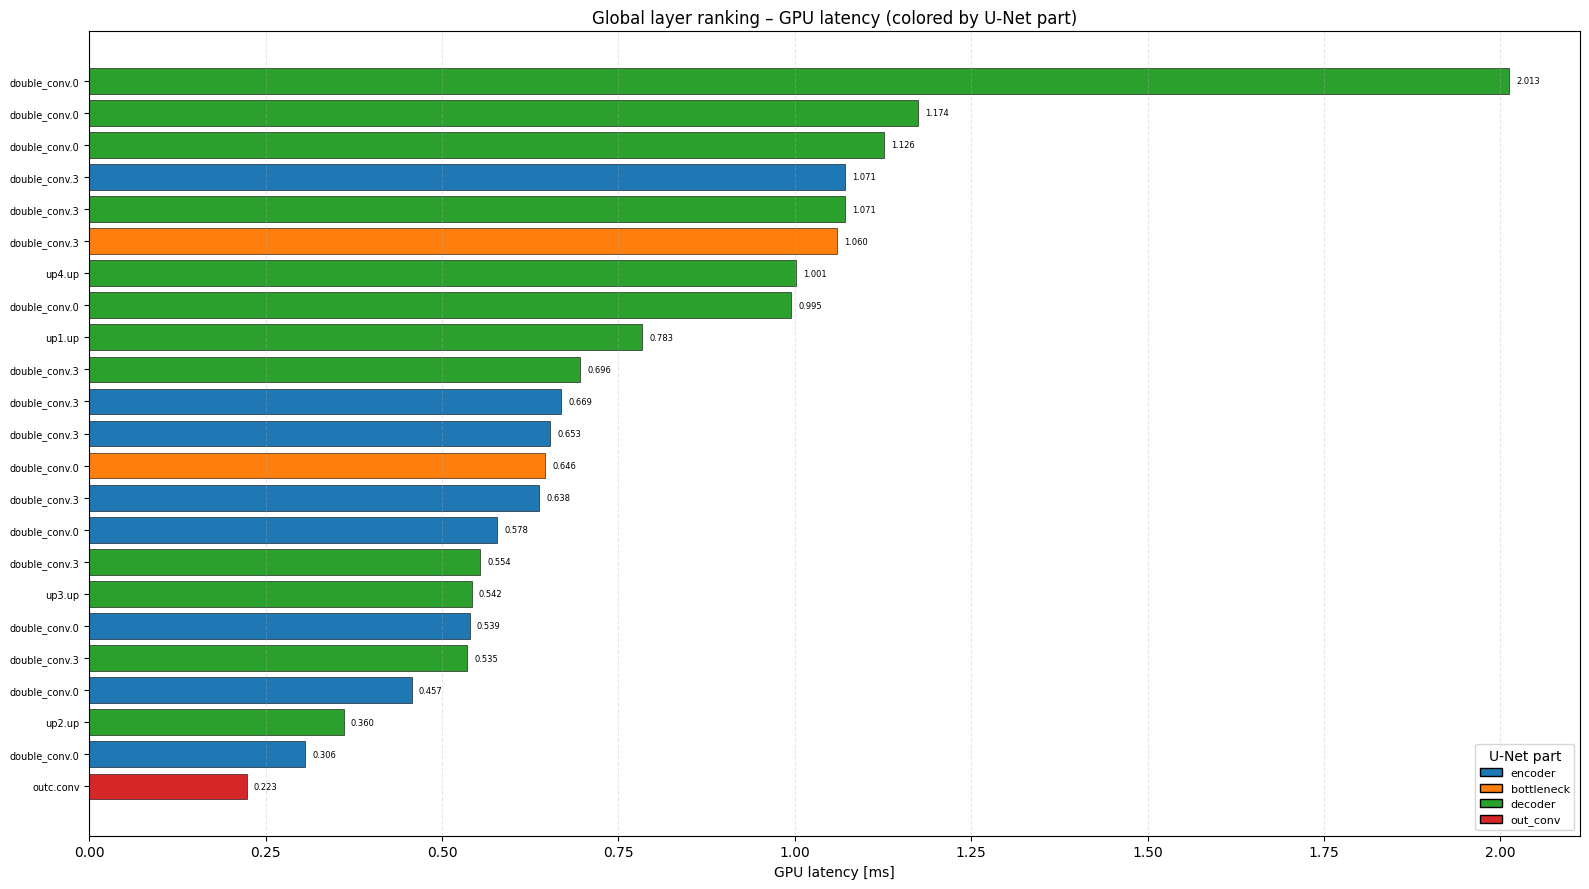

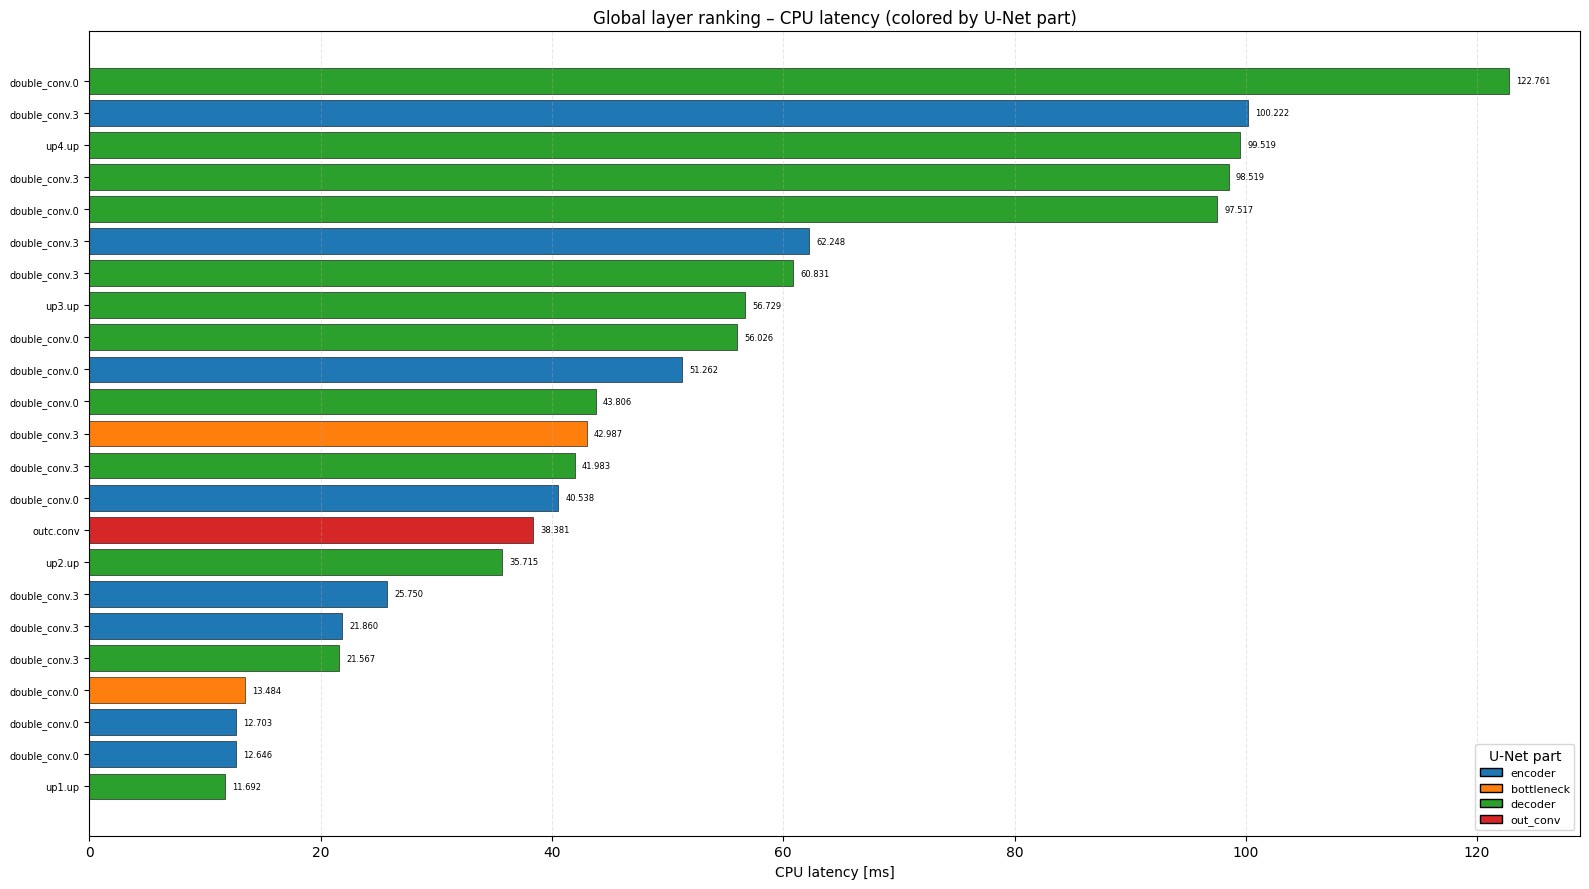

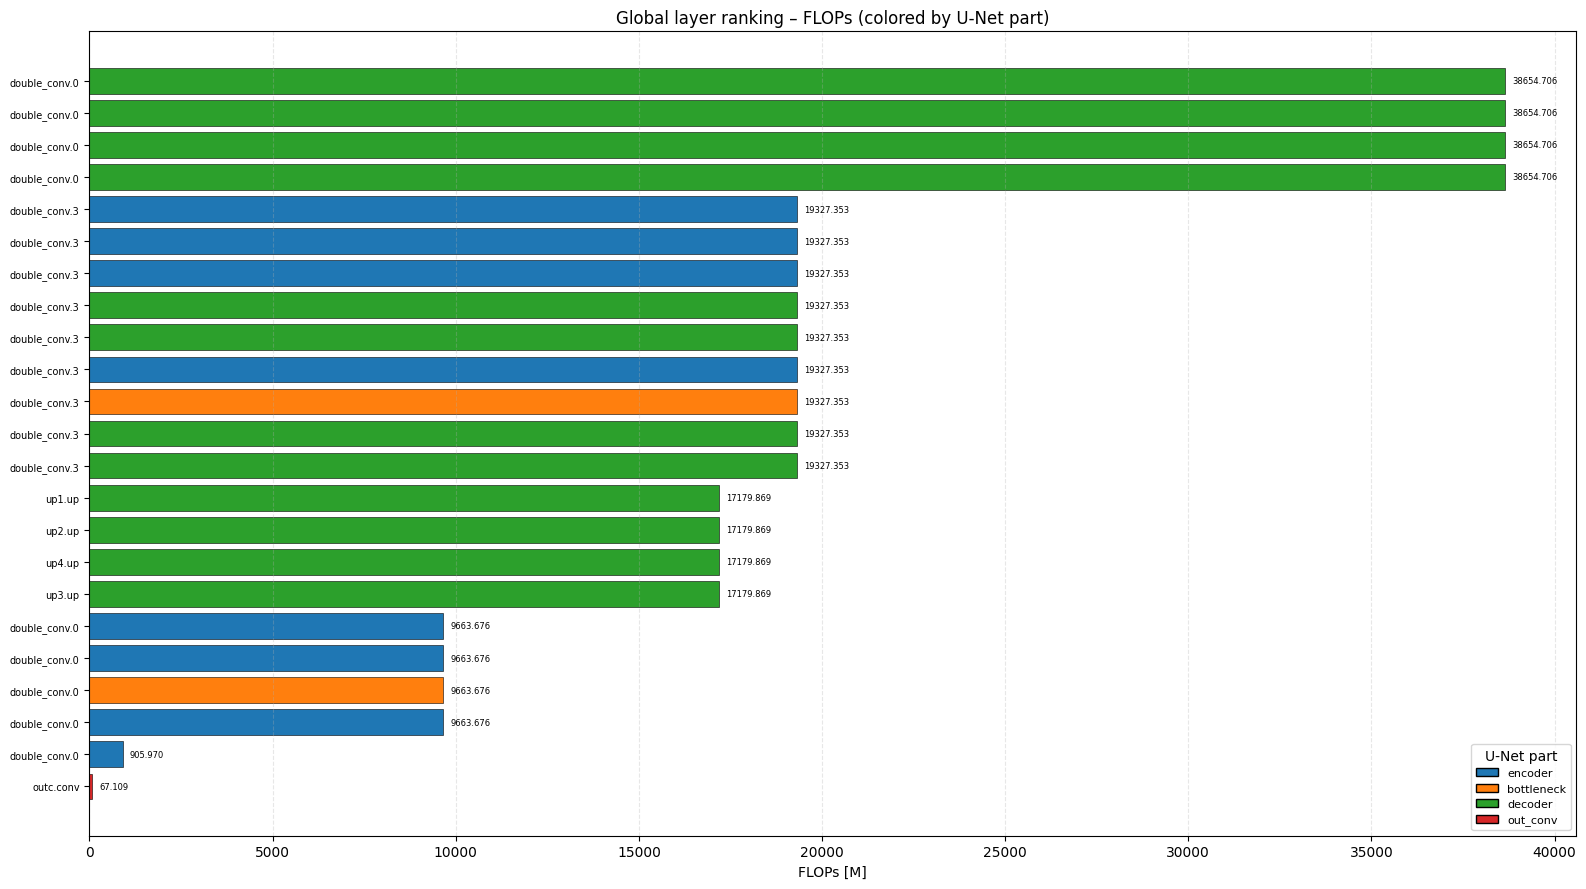

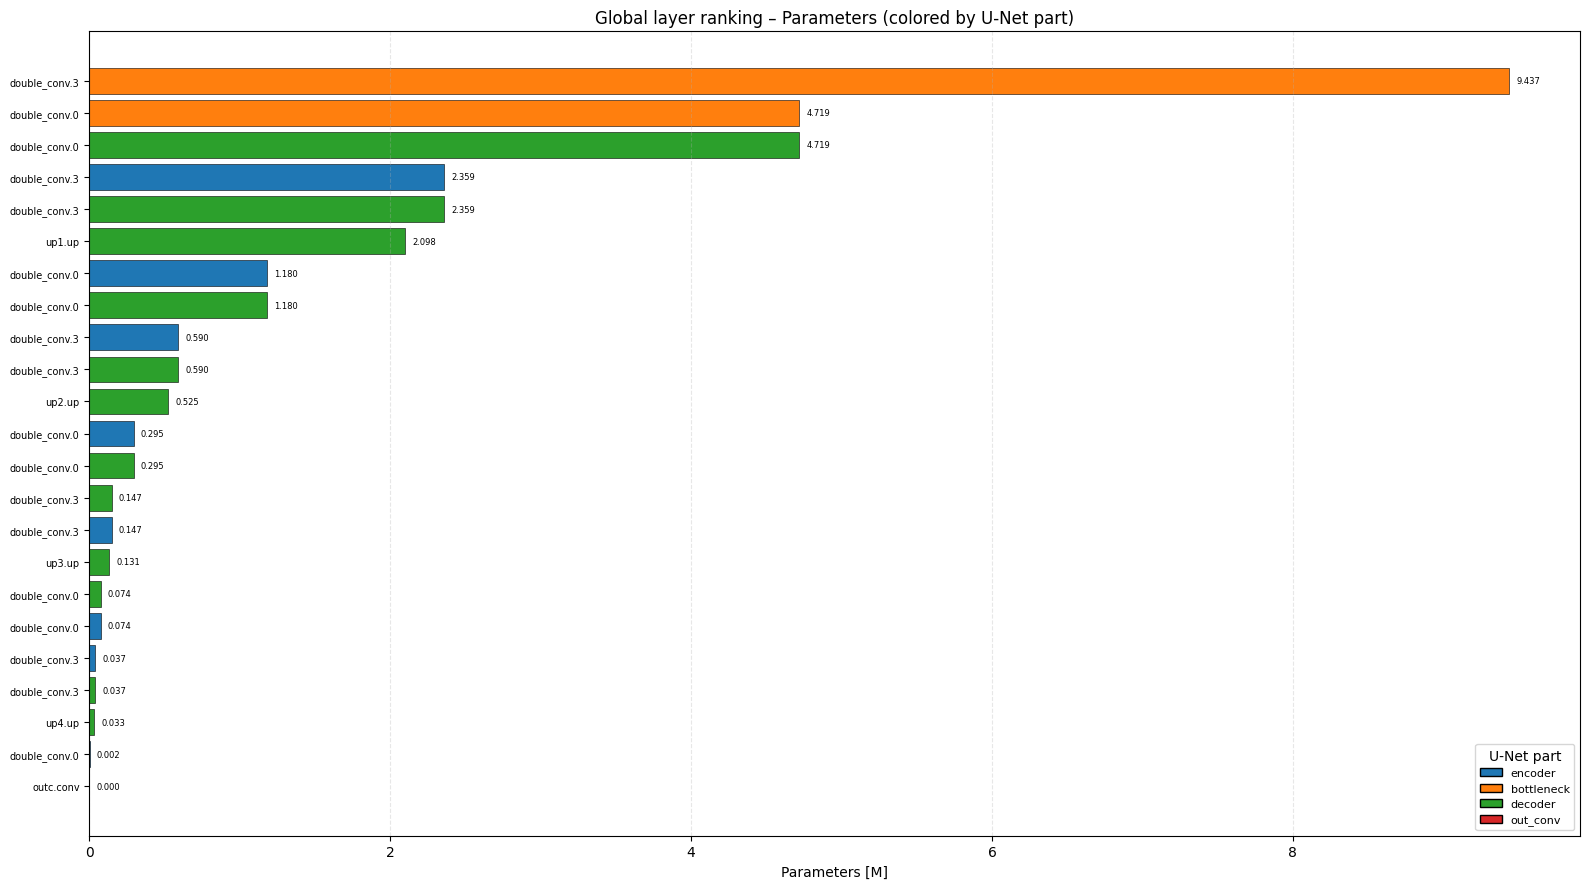

In [16]:
PART_COLORS = {
    'encoder'    : 'tab:blue',
    'bottleneck' : 'tab:orange',
    'decoder'    : 'tab:green',
    'out_conv'   : 'tab:red',
    'unknown'    : 'gray',
}


def plot_global_ranking(df_sorted: pd.DataFrame,
                        value_col: str,
                        ylabel: str,
                        title: str,
                        part_colors: dict,
                        top_n: int = None,
                        figsize=(16, 5)):
    """
    Horizontal bar chart, one bar per layer, ordered by value_col (desc).
    Bars are colored by U-Net part.  Legend shows part membership.
    top_n: if set, show only the top-N most expensive layers.
    """
    df = df_sorted.copy()
    if top_n is not None:
        df = df.head(top_n)

    # Short labels: last two path components
    labels = [
        '.'.join(n.split('.')[-2:]) if n.count('.') >= 2 else n
        for n in df['layer_name']
    ]
    colors = [part_colors.get(p, 'gray') for p in df['part']]
    values = df[value_col].values

    fig, ax = plt.subplots(figsize=figsize)
    y_pos = np.arange(len(labels))
    bars = ax.barh(y_pos, values, color=colors, edgecolor='black', linewidth=0.4)

    for bar, v in zip(bars, values):
        ax.text(bar.get_width() + values.max() * 0.005, bar.get_y() + bar.get_height() / 2,
                f'{v:.3f}', va='center', fontsize=6)

    ax.set_yticks(y_pos)
    ax.set_yticklabels(labels, fontsize=7)
    ax.invert_yaxis()  # rank-1 on top
    ax.set_xlabel(ylabel)
    ax.set_title(title)
    ax.grid(axis='x', linestyle='--', alpha=0.3)

    # Legend
    from matplotlib.patches import Patch
    legend_handles = [
        Patch(facecolor=c, edgecolor='black', label=p)
        for p, c in part_colors.items()
        if p in df['part'].values
    ]
    ax.legend(handles=legend_handles, loc='lower right', fontsize=8, title='U-Net part')

    plt.tight_layout()
    plt.show()


# ── GPU Latency ranking ───────────────────────────────────────────────────
plot_global_ranking(
    df_ranked_gpu, 'time_gpu_ms', 'GPU latency [ms]',
    'Global layer ranking – GPU latency (colored by U-Net part)',
    PART_COLORS, figsize=(16, 9)
)

# ── CPU Latency ranking ───────────────────────────────────────────────────
df_ranked_cpu = df_layers.sort_values('time_cpu_ms', ascending=False).reset_index(drop=True)
plot_global_ranking(
    df_ranked_cpu, 'time_cpu_ms', 'CPU latency [ms]',
    'Global layer ranking – CPU latency (colored by U-Net part)',
    PART_COLORS, figsize=(16, 9)
)

# ── FLOPs ranking ────────────────────────────────────────────────────────
plot_global_ranking(
    df_ranked_flops, 'flops_M', 'FLOPs [M]',
    'Global layer ranking – FLOPs (colored by U-Net part)',
    PART_COLORS, figsize=(16, 9)
)

# ── Parameters ranking ───────────────────────────────────────────────────
plot_global_ranking(
    df_ranked_params, 'params_M', 'Parameters [M]',
    'Global layer ranking – Parameters (colored by U-Net part)',
    PART_COLORS, figsize=(16, 9)
)

### 2.7  Within-part ranking (secondary reference)

Same layers, but now the ranking is **within each part** so you can see
which layers are cheapest/most expensive *relative to their neighbours*.
The global rank is still shown for cross-part comparison.

In [17]:
# ── Within-part rank columns ────────────────────────────────────────────
for metric in ('params_M', 'flops_M', 'time_gpu_ms', 'time_cpu_ms'):
    df_layers[f'part_rank_{metric}'] = (
        df_layers.groupby('part')[metric]
        .rank(ascending=False, method='min')
        .astype(int)
    )

# ── Print within-part table for each part ──────────────────────────────
detail_cols = [
    'part_rank_time_gpu_ms', 'rank_time_gpu_ms',
    'layer_name', 'type', 'in_ch', 'out_ch', 'kernel',
    'params_M', 'flops_M', 'time_gpu_ms'
]

for part in ('encoder', 'bottleneck', 'decoder', 'out_conv'):
    subset = (
        df_layers[df_layers['part'] == part]
        .sort_values('time_gpu_ms', ascending=False)
        .reset_index(drop=True)
    )
    if subset.empty:
        continue
    print(f'\n=== Within-part ranking: {part.upper()} ===')
    display(subset[detail_cols])


=== Within-part ranking: ENCODER ===


,part_rank_time_gpu_ms,rank_time_gpu_ms,layer_name,type,in_ch,out_ch,kernel,params_M,flops_M,time_gpu_ms
0,1,4,inc.double_conv.3,Conv2d,64,64,"(3, 3)",0.036864,19327.352832,1.070972
1,2,11,down3.maxpool_conv.1.double_conv.3,Conv2d,512,512,"(3, 3)",2.359296,19327.352832,0.669038
2,3,12,down2.maxpool_conv.1.double_conv.3,Conv2d,256,256,"(3, 3)",0.589824,19327.352832,0.652782
3,4,14,down1.maxpool_conv.1.double_conv.3,Conv2d,128,128,"(3, 3)",0.147456,19327.352832,0.637844
4,5,15,inc.double_conv.0,Conv2d,3,64,"(3, 3)",0.001728,905.969664,0.578447
5,6,18,down1.maxpool_conv.1.double_conv.0,Conv2d,64,128,"(3, 3)",0.073728,9663.676416,0.539135
6,7,20,down3.maxpool_conv.1.double_conv.0,Conv2d,256,512,"(3, 3)",1.179648,9663.676416,0.456987
7,8,22,down2.maxpool_conv.1.double_conv.0,Conv2d,128,256,"(3, 3)",0.294912,9663.676416,0.306245



=== Within-part ranking: BOTTLENECK ===


,part_rank_time_gpu_ms,rank_time_gpu_ms,layer_name,type,in_ch,out_ch,kernel,params_M,flops_M,time_gpu_ms
0,1,6,down4.maxpool_conv.1.double_conv.3,Conv2d,1024,1024,"(3, 3)",9.437184,19327.352832,1.060003
1,2,13,down4.maxpool_conv.1.double_conv.0,Conv2d,512,1024,"(3, 3)",4.718592,9663.676416,0.645700



=== Within-part ranking: DECODER ===


,part_rank_time_gpu_ms,rank_time_gpu_ms,layer_name,type,in_ch,out_ch,kernel,params_M,flops_M,time_gpu_ms
0,1,1,up4.conv.double_conv.0,Conv2d,128,64,"(3, 3)",0.073728,38654.705664,2.012511
1,2,2,up3.conv.double_conv.0,Conv2d,256,128,"(3, 3)",0.294912,38654.705664,1.174030
2,3,3,up1.conv.double_conv.0,Conv2d,1024,512,"(3, 3)",4.718592,38654.705664,1.126401
3,4,5,up4.conv.double_conv.3,Conv2d,64,64,"(3, 3)",0.036864,19327.352832,1.070891
4,5,7,up4.up,ConvTranspose2d,128,64,"(2, 2)",0.032832,17179.869184,1.001425
5,6,8,up2.conv.double_conv.0,Conv2d,512,256,"(3, 3)",1.179648,38654.705664,0.994533
6,7,9,up1.up,ConvTranspose2d,1024,512,"(2, 2)",2.097664,17179.869184,0.783440
7,8,10,up3.conv.double_conv.3,Conv2d,128,128,"(3, 3)",0.147456,19327.352832,0.696098
8,9,16,up1.conv.double_conv.3,Conv2d,512,512,"(3, 3)",2.359296,19327.352832,0.554203
9,10,17,up3.up,ConvTranspose2d,256,128,"(2, 2)",0.131200,17179.869184,0.541720



=== Within-part ranking: OUT_CONV ===


,part_rank_time_gpu_ms,rank_time_gpu_ms,layer_name,type,in_ch,out_ch,kernel,params_M,flops_M,time_gpu_ms
0,1,23,outc.conv,Conv2d,64,2,"(1, 1)",0.00013,67.108864,0.222919


### 2.8  Within-part ranking – visual (GPU latency)

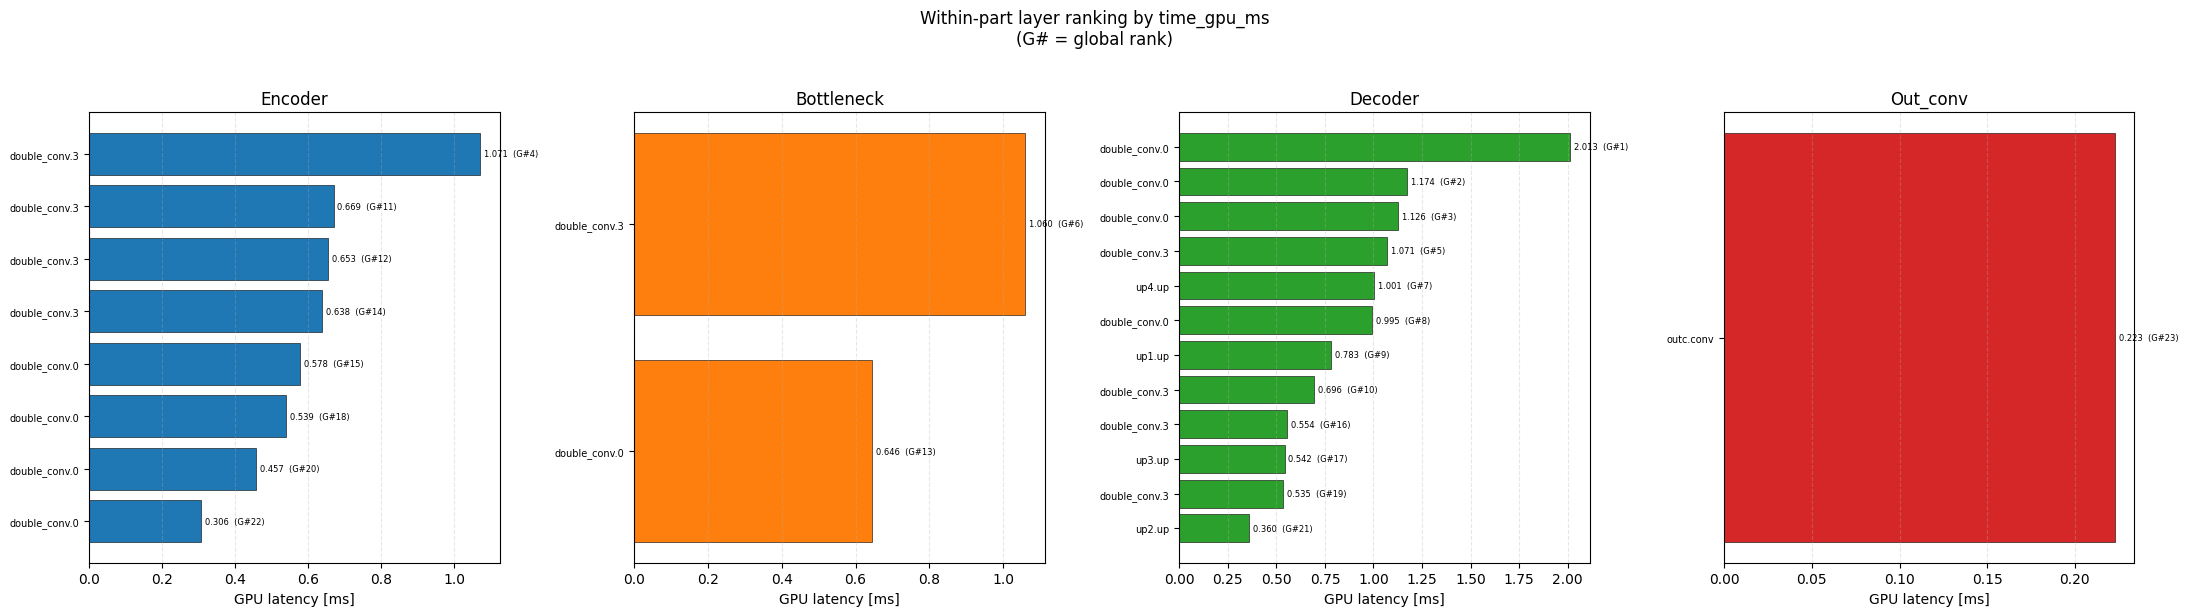

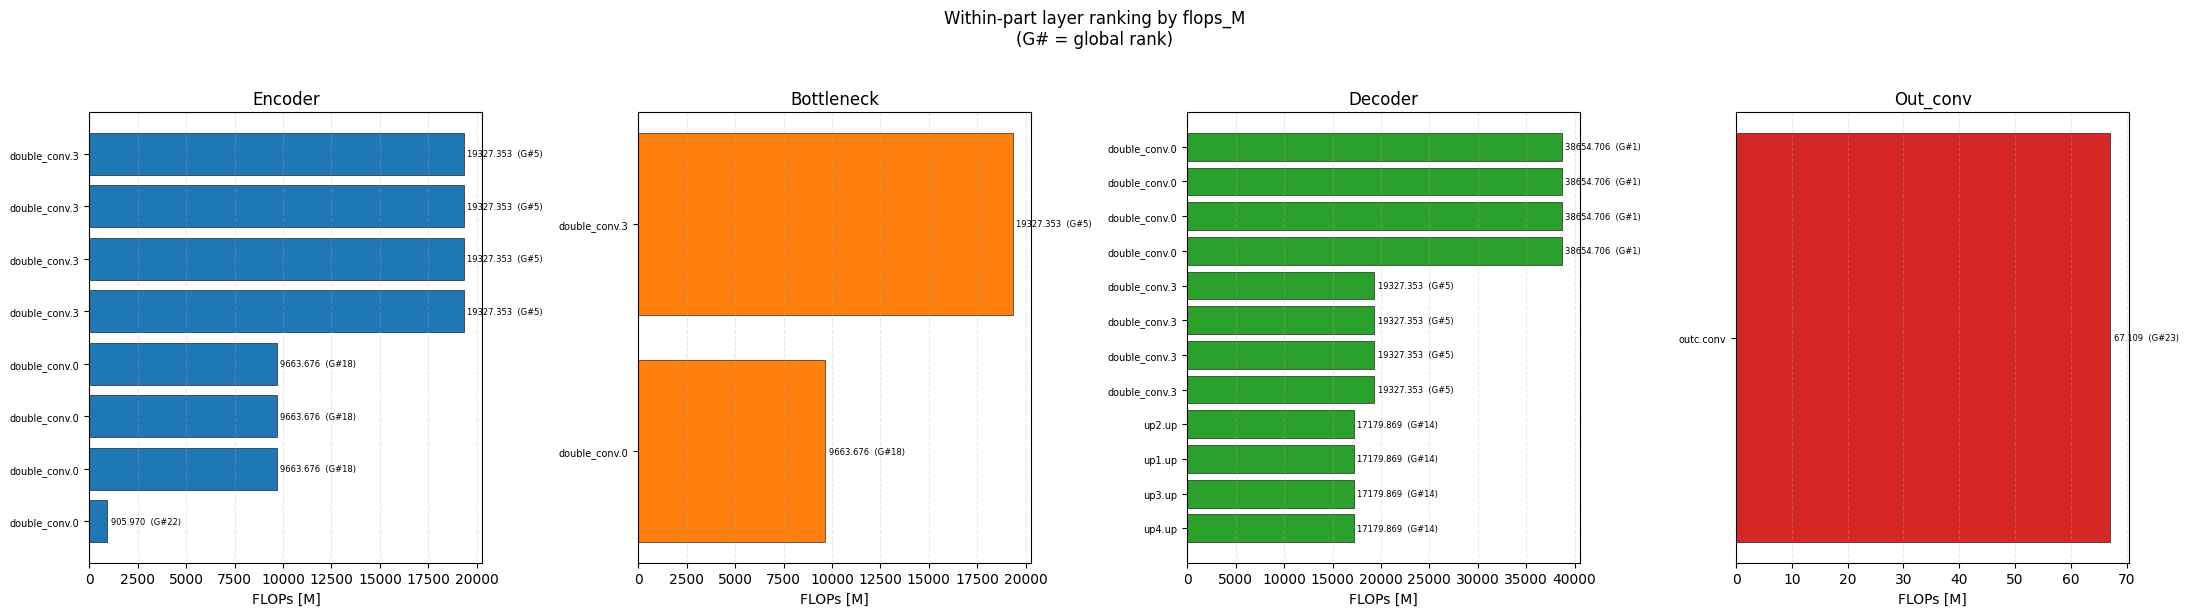

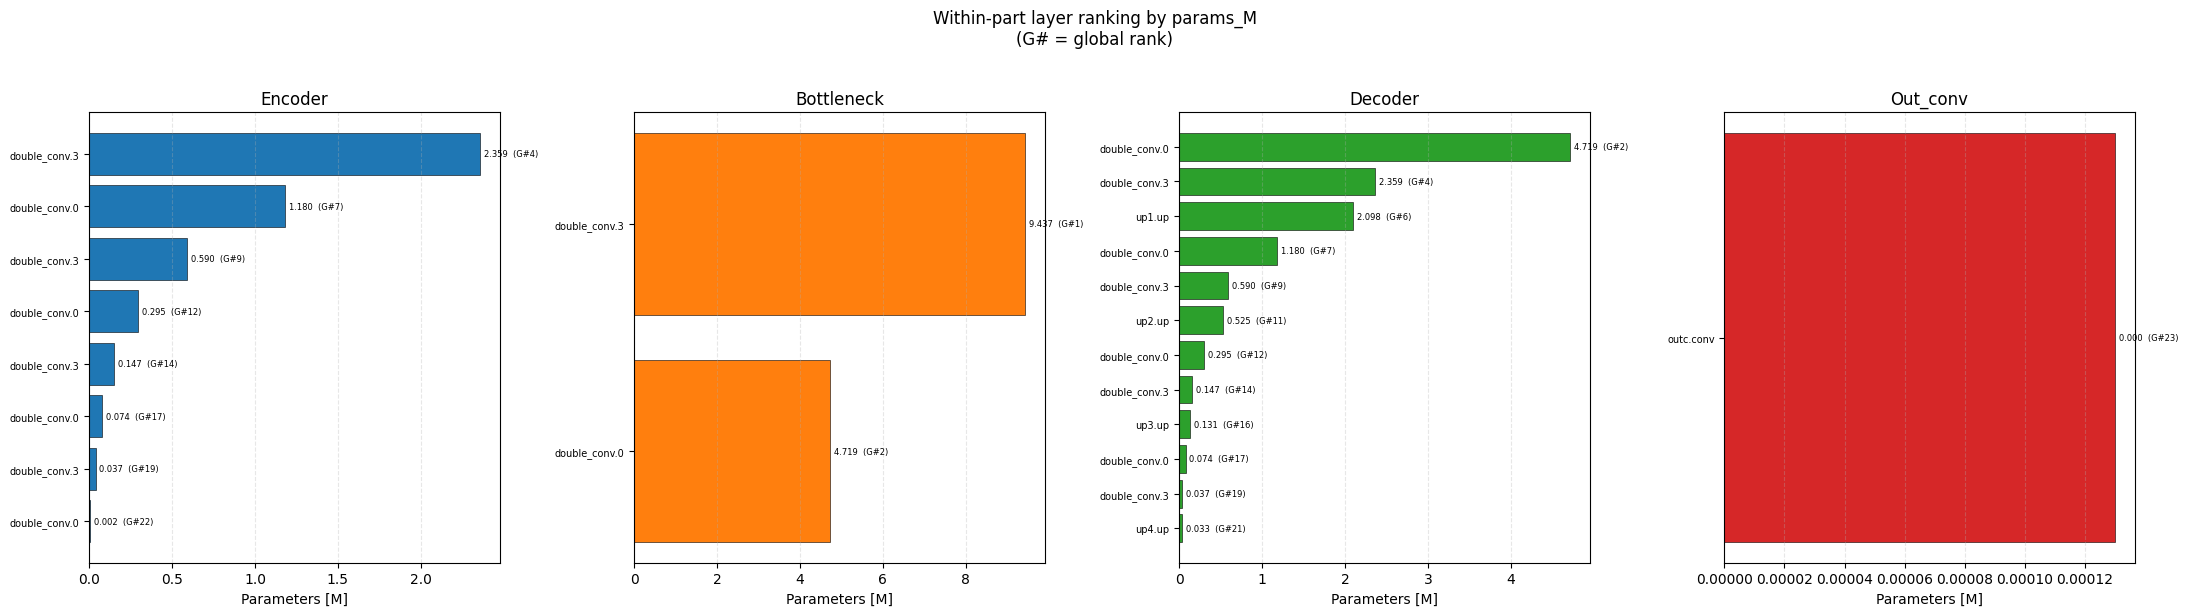

In [18]:
def plot_within_part_ranking(df_layers: pd.DataFrame,
                             value_col: str,
                             ylabel: str,
                             part_colors: dict,
                             figsize=(18, 5)):
    """
    One subplot per U-Net part.  Within each subplot layers are ranked
    descending by value_col.  Global rank shown in bar label.
    """
    parts = ['encoder', 'bottleneck', 'decoder', 'out_conv']
    parts = [p for p in parts if p in df_layers['part'].values]
    n = len(parts)

    fig, axes = plt.subplots(1, n, figsize=figsize, sharey=False)
    if n == 1:
        axes = [axes]

    global_rank_col = f'rank_{value_col}'

    for ax, part in zip(axes, parts):
        sub = (
            df_layers[df_layers['part'] == part]
            .sort_values(value_col, ascending=False)
            .reset_index(drop=True)
        )
        labels = [
            '.'.join(n.split('.')[-2:]) if n.count('.') >= 2 else n
            for n in sub['layer_name']
        ]
        values = sub[value_col].values
        g_ranks = sub[global_rank_col].values if global_rank_col in sub else None
        color   = part_colors.get(part, 'gray')

        y_pos = np.arange(len(labels))
        bars = ax.barh(y_pos, values, color=color, edgecolor='black', linewidth=0.4)

        for i, (bar, v) in enumerate(zip(bars, values)):
            label_str = f'{v:.3f}'
            if g_ranks is not None:
                label_str += f'  (G#{g_ranks[i]})'
            ax.text(bar.get_width() + values.max() * 0.01,
                    bar.get_y() + bar.get_height() / 2,
                    label_str, va='center', fontsize=6)

        ax.set_yticks(y_pos)
        ax.set_yticklabels(labels, fontsize=7)
        ax.invert_yaxis()
        ax.set_xlabel(ylabel)
        ax.set_title(part.capitalize())
        ax.grid(axis='x', linestyle='--', alpha=0.3)

    fig.suptitle(f'Within-part layer ranking by {value_col}\n(G# = global rank)', y=1.02)
    plt.tight_layout()
    plt.show()


plot_within_part_ranking(
    df_layers, 'time_gpu_ms', 'GPU latency [ms]', PART_COLORS, figsize=(22, 6)
)
plot_within_part_ranking(
    df_layers, 'flops_M', 'FLOPs [M]', PART_COLORS, figsize=(22, 6)
)
plot_within_part_ranking(
    df_layers, 'params_M', 'Parameters [M]', PART_COLORS, figsize=(22, 6)
)

### 2.9  Cumulative cost – top-K layers cover X% of total cost

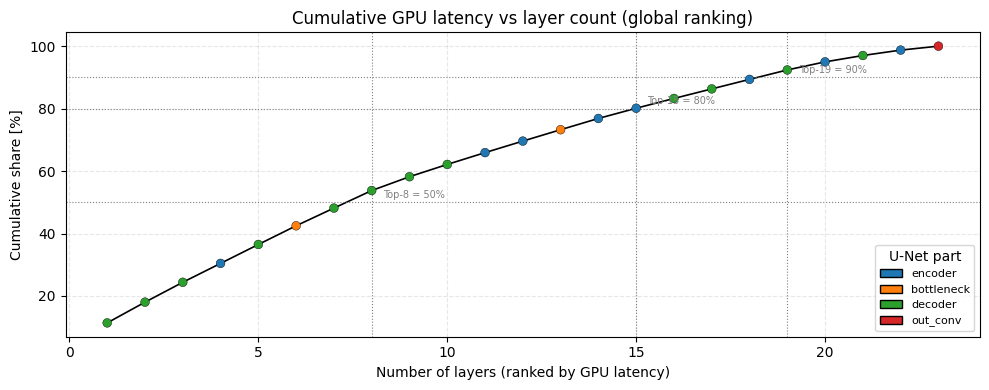

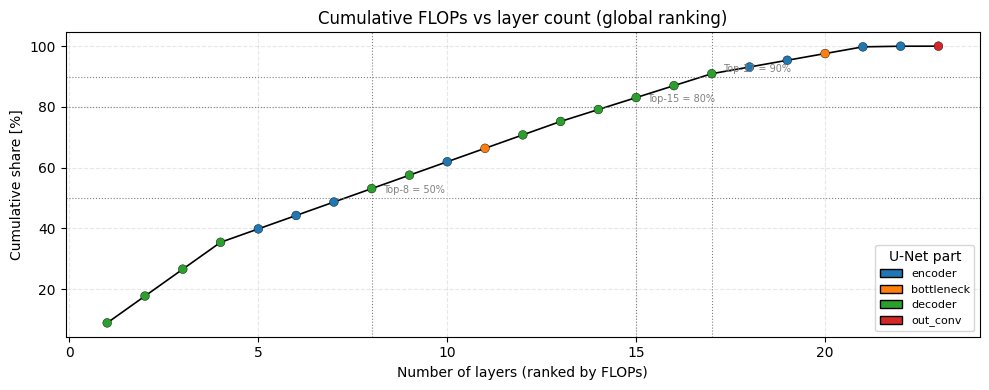

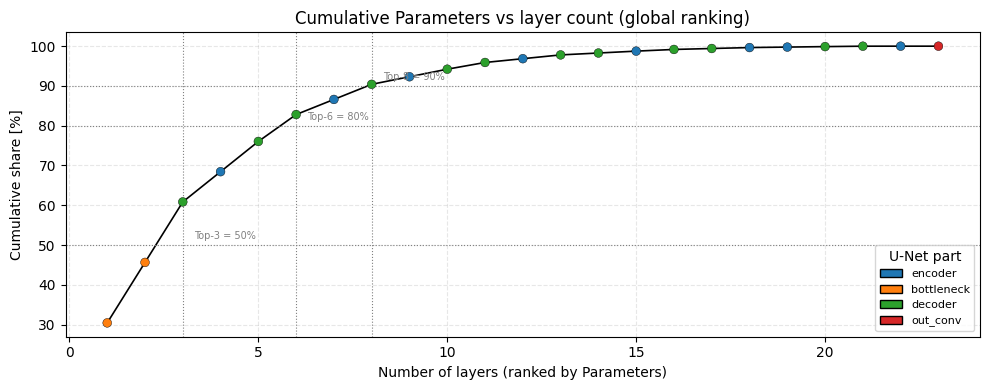

In [19]:
def plot_cumulative_cost(df_ranked: pd.DataFrame,
                         value_col: str,
                         xlabel: str,
                         part_colors: dict,
                         title: str,
                         figsize=(10, 4)):
    """
    Cumulative % of total cost as layers are added (most expensive first).
    Dots are colored by part.
    """
    vals   = df_ranked[value_col].values
    parts  = df_ranked['part'].values
    total  = vals.sum()
    cumsum = np.cumsum(vals) / (total + 1e-12) * 100.0
    colors = [part_colors.get(p, 'gray') for p in parts]

    fig, ax = plt.subplots(figsize=figsize)
    ax.plot(np.arange(1, len(cumsum) + 1), cumsum, color='black', linewidth=1.2, zorder=2)
    ax.scatter(np.arange(1, len(cumsum) + 1), cumsum,
               c=colors, s=40, zorder=3, edgecolors='black', linewidths=0.3)

    for thr in (50, 80, 90):
        idx = np.searchsorted(cumsum, thr)
        if idx < len(cumsum):
            ax.axhline(thr, color='gray', linestyle=':', linewidth=0.8)
            ax.axvline(idx + 1, color='gray', linestyle=':', linewidth=0.8)
            ax.text(idx + 1.3, thr + 1.5,
                    f'Top-{idx+1} = {thr}%', fontsize=7, color='gray')

    ax.set_xlabel(xlabel)
    ax.set_ylabel('Cumulative share [%]')
    ax.set_title(title)
    ax.grid(linestyle='--', alpha=0.3)

    from matplotlib.patches import Patch
    legend_handles = [
        Patch(facecolor=c, edgecolor='black', label=p)
        for p, c in part_colors.items()
        if p in df_ranked['part'].values
    ]
    ax.legend(handles=legend_handles, fontsize=8, title='U-Net part')

    plt.tight_layout()
    plt.show()


plot_cumulative_cost(
    df_ranked_gpu, 'time_gpu_ms', 'Number of layers (ranked by GPU latency)',
    PART_COLORS, 'Cumulative GPU latency vs layer count (global ranking)', figsize=(10, 4)
)
plot_cumulative_cost(
    df_ranked_flops, 'flops_M', 'Number of layers (ranked by FLOPs)',
    PART_COLORS, 'Cumulative FLOPs vs layer count (global ranking)', figsize=(10, 4)
)
plot_cumulative_cost(
    df_ranked_params, 'params_M', 'Number of layers (ranked by Parameters)',
    PART_COLORS, 'Cumulative Parameters vs layer count (global ranking)', figsize=(10, 4)
)

### 2.10  Summary: part-level aggregate from individual layer profiling

This re-creates the macro-section view but derived bottom-up from the per-layer
measurements, so both levels are consistent.

In [20]:
df_part_summary = (
    df_layers
    .groupby('part', sort=False)
    .agg(
        n_layers       = ('layer_name', 'count'),
        params_M_total = ('params_M',    'sum'),
        flops_M_total  = ('flops_M',     'sum'),
        time_gpu_ms    = ('time_gpu_ms', 'sum'),
        time_cpu_ms    = ('time_cpu_ms', 'sum'),
    )
    .reset_index()
)

# Share columns
for metric in ('params_M_total', 'flops_M_total', 'time_gpu_ms', 'time_cpu_ms'):
    total = df_part_summary[metric].sum()
    df_part_summary[f'{metric}_share%'] = (
        100.0 * df_part_summary[metric] / (total + 1e-12)
    ).round(1)

# Enforce logical order
order = ['encoder', 'bottleneck', 'decoder', 'out_conv']
df_part_summary['_ord'] = df_part_summary['part'].map(
    {p: i for i, p in enumerate(order)}
).fillna(99)
df_part_summary = df_part_summary.sort_values('_ord').drop(columns='_ord').reset_index(drop=True)

print('Part-level summary (aggregated from individual layer measurements):')
df_part_summary

Part-level summary (aggregated from individual layer measurements):


,part,n_layers,params_M_total,flops_M_total,time_gpu_ms,time_cpu_ms,params_M_total_share%,flops_M_total_share%,time_gpu_ms_share%,time_cpu_ms_share%
0,encoder,8,4.683456,107206.410240,4.911449,327.229404,15.1,24.5,27.8,28.0
1,bottleneck,2,14.155776,28991.029248,1.705703,56.470461,45.6,6.6,9.6,4.8
2,decoder,12,12.186560,300647.710720,10.850939,746.665195,39.3,68.8,61.3,63.9
3,out_conv,1,0.000130,67.108864,0.222919,38.380930,0.0,0.0,1.3,3.3


### 2.11  Pruning budget guidance table

Ranks layers globally by GPU latency and recommends a pruning budget
proportional to their cost share, while showing which U-Net part each
layer belongs to as a structural reference.

In [21]:
def build_pruning_budget_table(df_layers: pd.DataFrame,
                               rank_by: str = 'time_gpu_ms') -> pd.DataFrame:
    """
    Returns a DataFrame with suggested pruning budget per layer.

    Budget logic:
      - Layers are sorted globally by `rank_by` (descending, most costly first).
      - suggested_sparsity = cost_share * 0.8  (clipped to [0.1, 0.7])
        meaning the most costly layers get the highest sparsity target.

    This is only a starting heuristic; accuracy-aware refinement should follow.
    """
    df = df_layers.sort_values(rank_by, ascending=False).copy().reset_index(drop=True)
    total = df[rank_by].sum()
    df['cost_share%'] = 100.0 * df[rank_by] / (total + 1e-12)

    # Sparsity heuristic: higher cost -> higher sparsity target
    max_share = df['cost_share%'].max()
    df['suggested_sparsity'] = (
        (df['cost_share%'] / max_share) * 0.7
    ).clip(0.1, 0.7).round(2)

    cols = [
        f'rank_{rank_by}', 'part', 'layer_name', 'type',
        'in_ch', 'out_ch', 'params_M', 'flops_M', rank_by,
        'cost_share%', 'suggested_sparsity',
        'part_rank_time_gpu_ms',
    ]
    cols = [c for c in cols if c in df.columns]
    return df[cols]


df_budget = build_pruning_budget_table(df_layers, rank_by='flops_M')
print('Pruning budget guidance table (ranked by flops_M):')
df_budget

Pruning budget guidance table (ranked by flops_M):


,rank_flops_M,part,layer_name,type,in_ch,out_ch,params_M,flops_M,flops_M,cost_share%,suggested_sparsity,part_rank_time_gpu_ms
0,1,decoder,up4.conv.double_conv.0,Conv2d,128,64,0.073728,38654.705664,38654.705664,8.847247,0.70,1
1,1,decoder,up1.conv.double_conv.0,Conv2d,1024,512,4.718592,38654.705664,38654.705664,8.847247,0.70,3
2,1,decoder,up2.conv.double_conv.0,Conv2d,512,256,1.179648,38654.705664,38654.705664,8.847247,0.70,6
3,1,decoder,up3.conv.double_conv.0,Conv2d,256,128,0.294912,38654.705664,38654.705664,8.847247,0.70,2
4,5,encoder,inc.double_conv.3,Conv2d,64,64,0.036864,19327.352832,19327.352832,4.423623,0.35,1
5,5,encoder,down2.maxpool_conv.1.double_conv.3,Conv2d,256,256,0.589824,19327.352832,19327.352832,4.423623,0.35,3
6,5,encoder,down1.maxpool_conv.1.double_conv.3,Conv2d,128,128,0.147456,19327.352832,19327.352832,4.423623,0.35,4
7,5,decoder,up4.conv.double_conv.3,Conv2d,64,64,0.036864,19327.352832,19327.352832,4.423623,0.35,4
8,5,decoder,up2.conv.double_conv.3,Conv2d,256,256,0.589824,19327.352832,19327.352832,4.423623,0.35,11
9,5,encoder,down3.maxpool_conv.1.double_conv.3,Conv2d,512,512,2.359296,19327.352832,19327.352832,4.423623,0.35,2


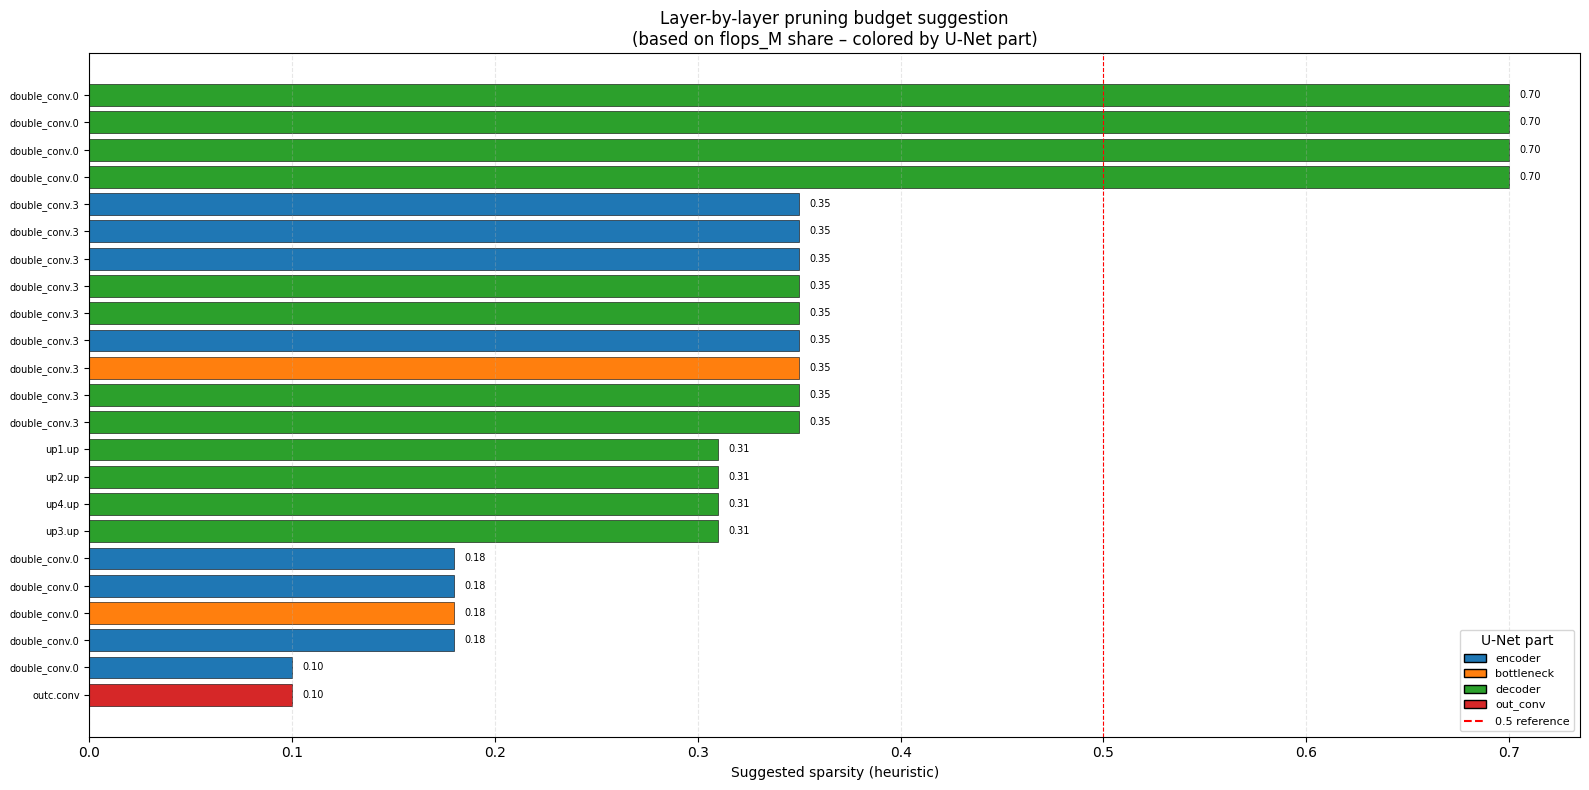

In [22]:
# ── Visualise suggested sparsity ──────────────────────────────────────────
labels = [
    '.'.join(n.split('.')[-2:]) if n.count('.') >= 2 else n
    for n in df_budget['layer_name']
]
colors  = [PART_COLORS.get(p, 'gray') for p in df_budget['part']]
spars   = df_budget['suggested_sparsity'].values

fig, ax = plt.subplots(figsize=(16, 8))
y_pos   = np.arange(len(labels))
bars    = ax.barh(y_pos, spars, color=colors, edgecolor='black', linewidth=0.4)

for bar, v in zip(bars, spars):
    ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height() / 2,
            f'{v:.2f}', va='center', fontsize=7)

ax.set_yticks(y_pos)
ax.set_yticklabels(labels, fontsize=7)
ax.invert_yaxis()
ax.set_xlabel('Suggested sparsity (heuristic)')
ax.set_title('Layer-by-layer pruning budget suggestion\n'
             '(based on flops_M share – colored by U-Net part)')
ax.axvline(0.5, color='red', linestyle='--', linewidth=0.8, label='0.5 reference')
ax.grid(axis='x', linestyle='--', alpha=0.3)

from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor=c, edgecolor='black', label=p)
    for p, c in PART_COLORS.items()
    if p in df_budget['part'].values
]
legend_handles.append(
    plt.Line2D([0], [0], color='red', linestyle='--', label='0.5 reference')
)
ax.legend(handles=legend_handles, loc='lower right', fontsize=8, title='U-Net part')

plt.tight_layout()
plt.show()

### 2.12  Export profiling results

### 2.13  Combined 4-metric per-layer grid

For every conv layer: a 2-row × 4-col grid showing FLOPs, Params, GPU latency, CPU latency — absolute (row 0) and as % of model total (row 1).  A dashed red line marks the cross-layer mean for reference.

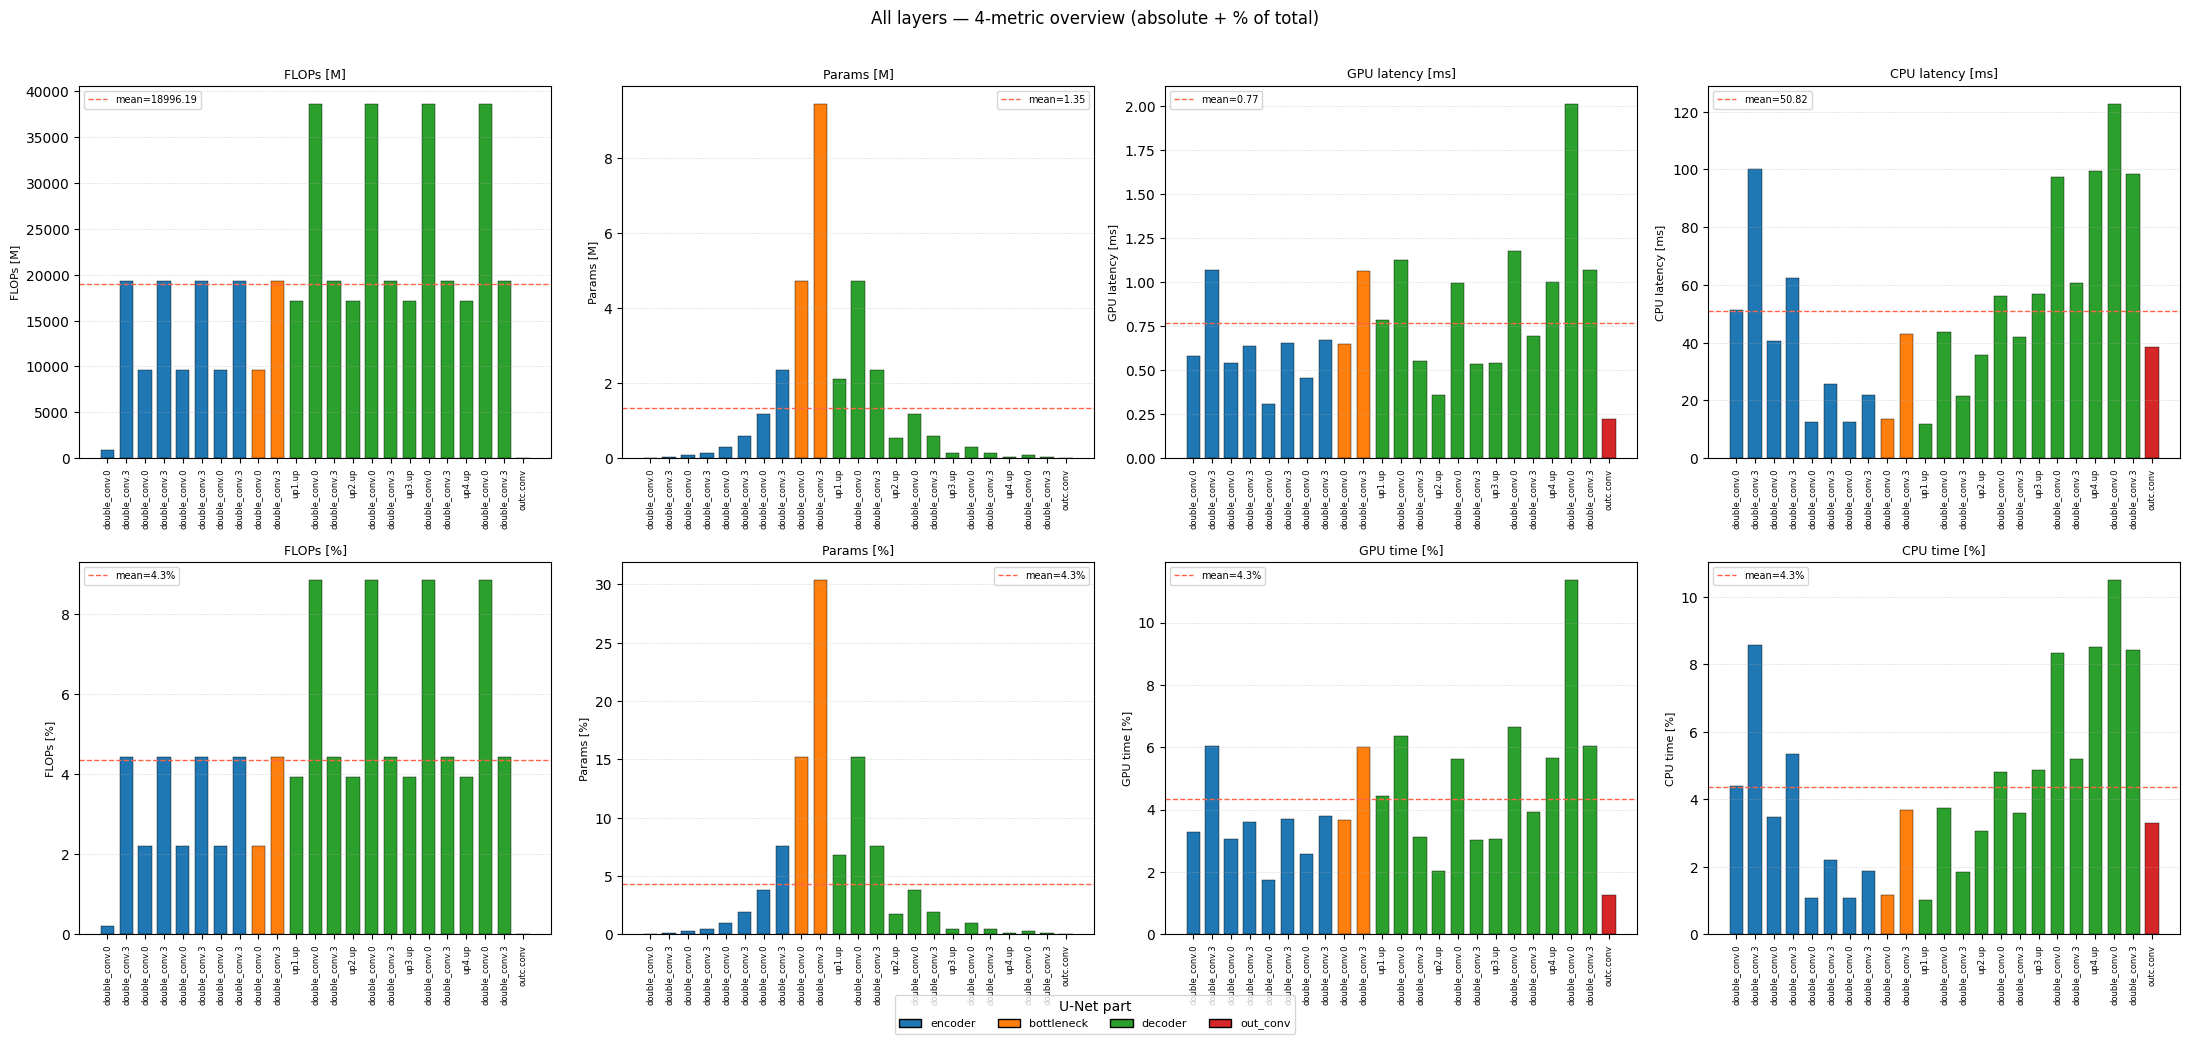

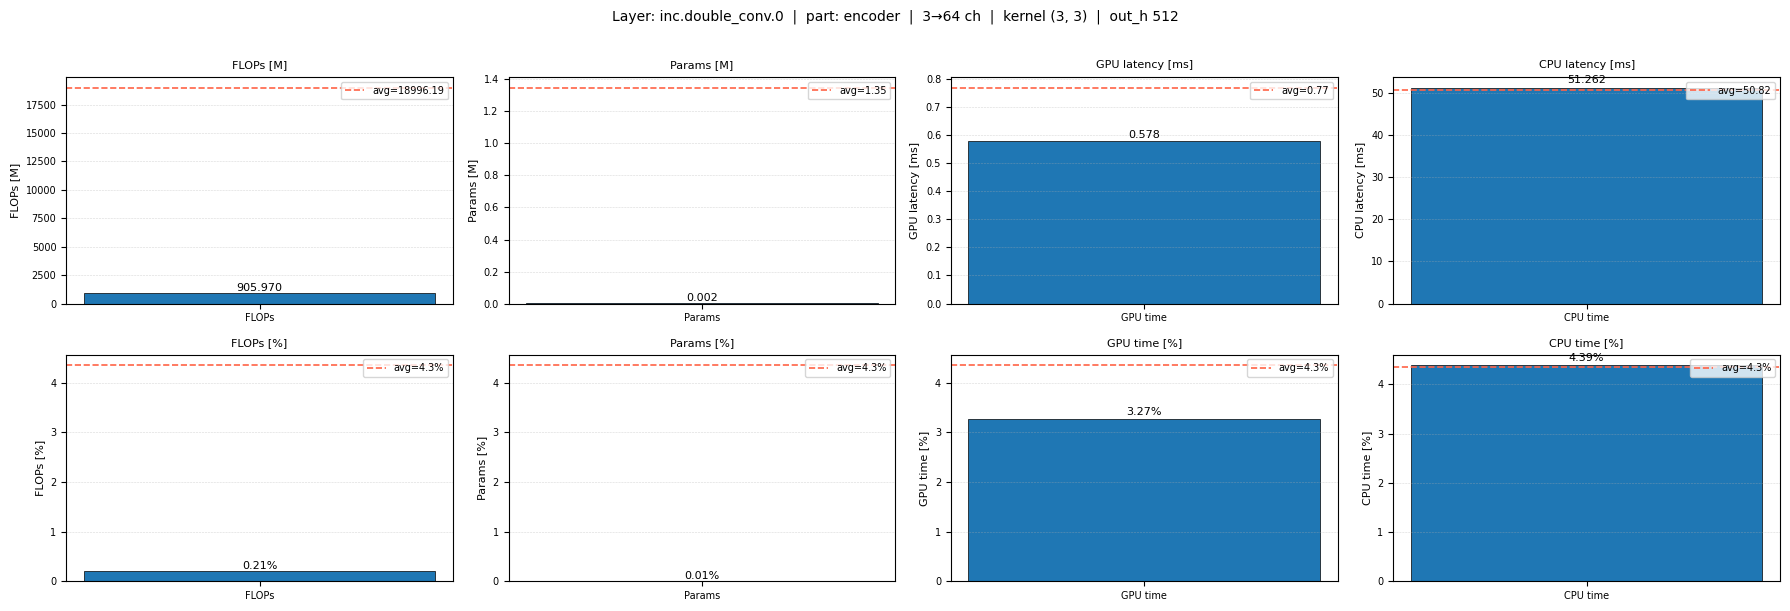

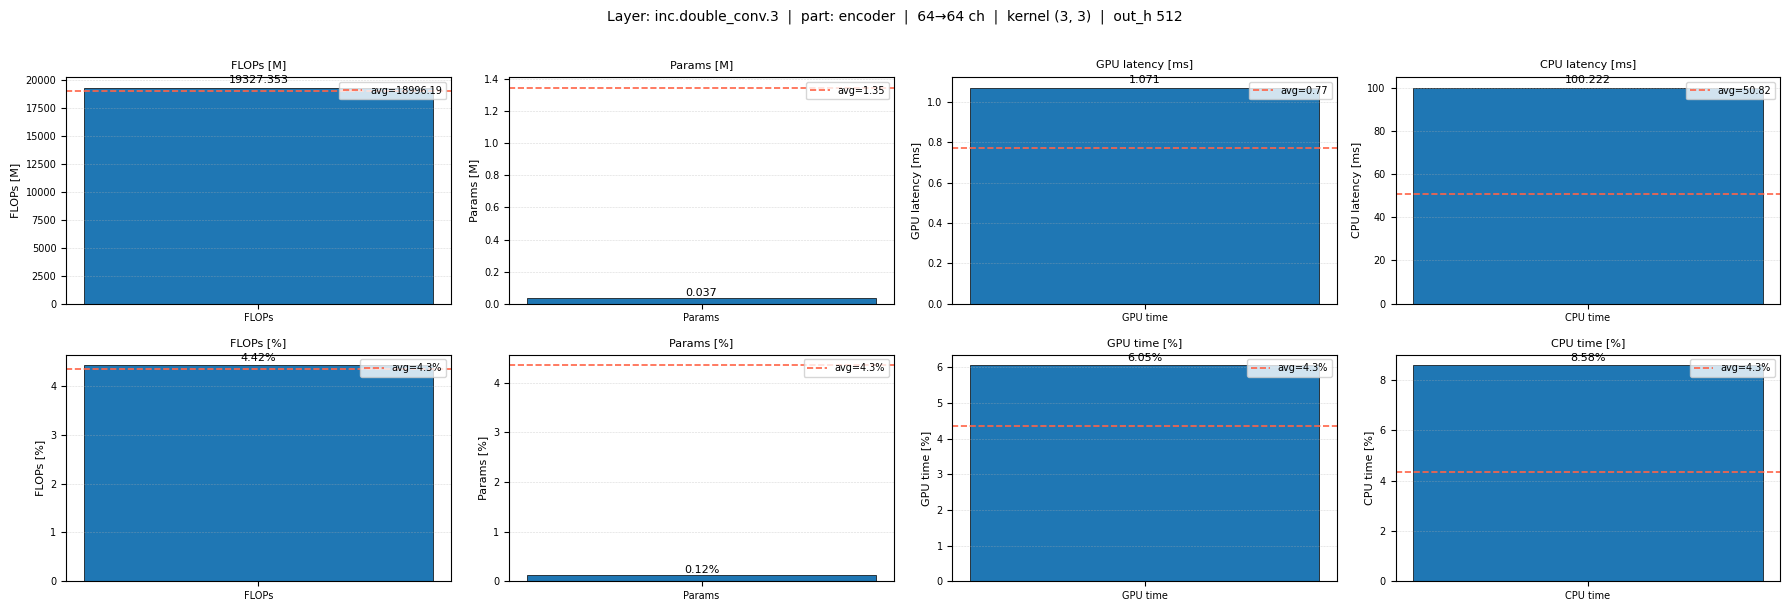

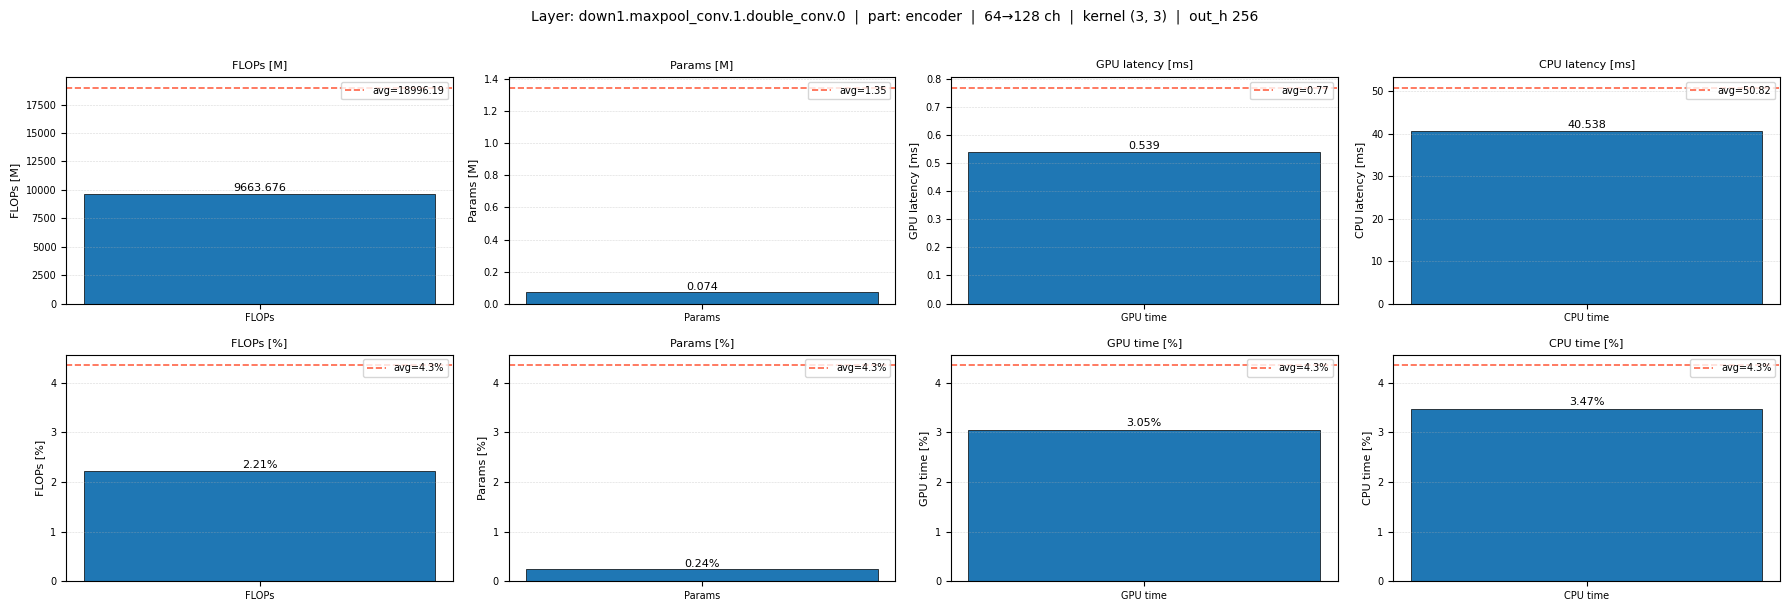

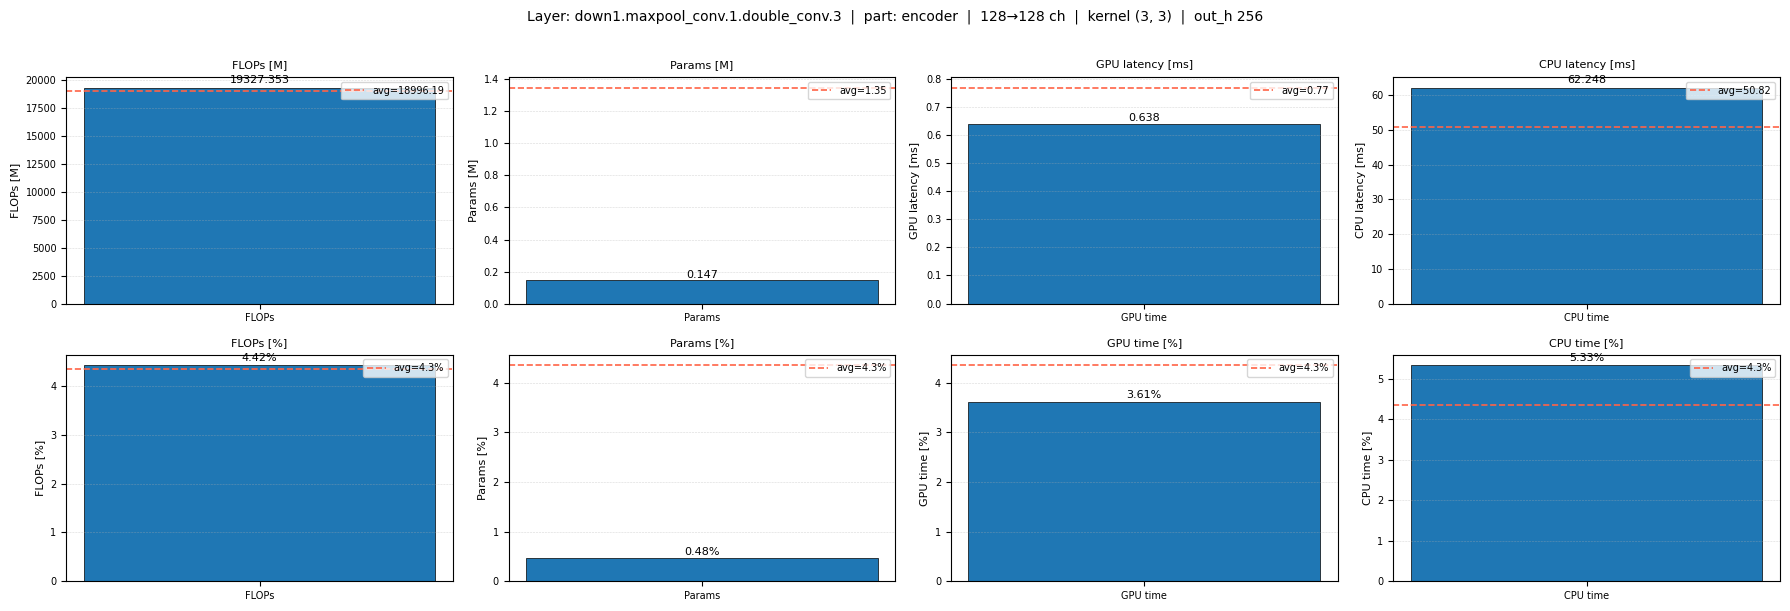

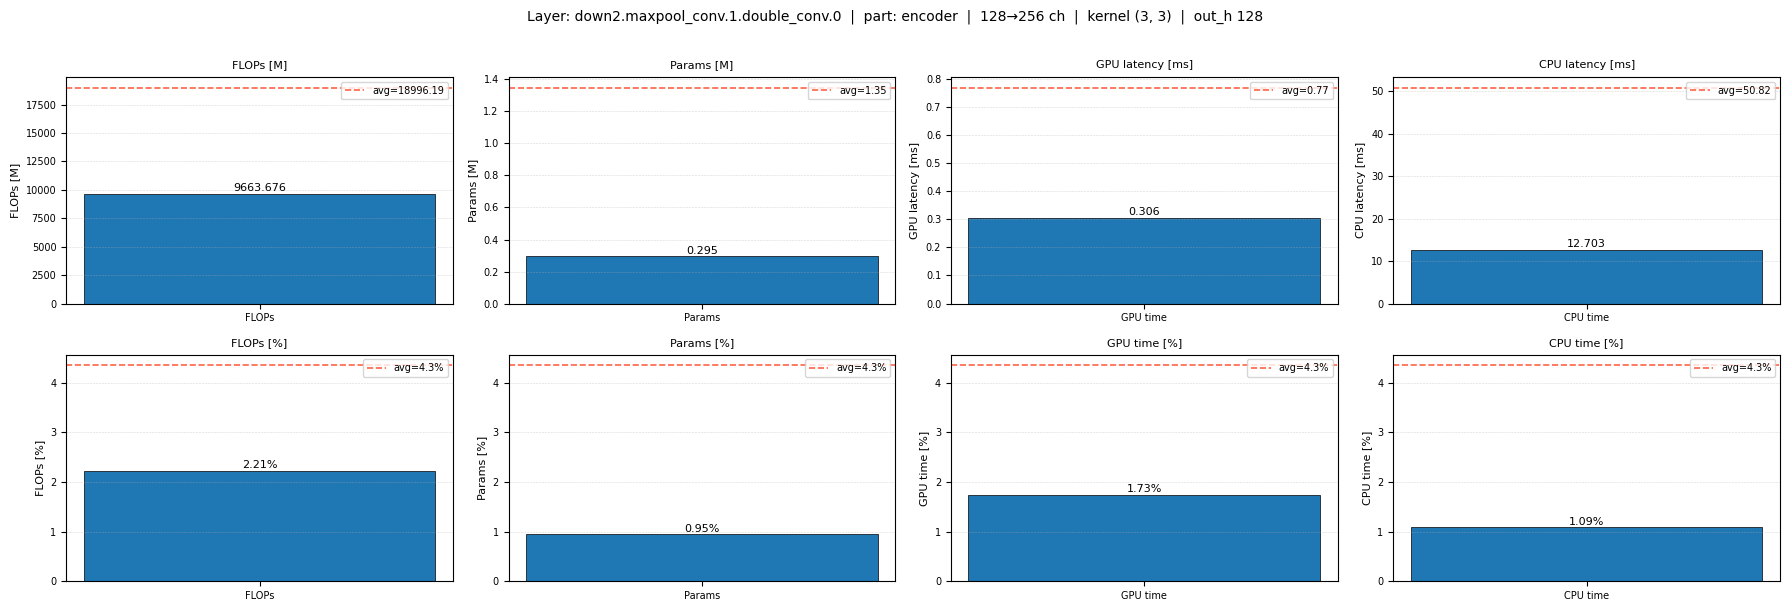

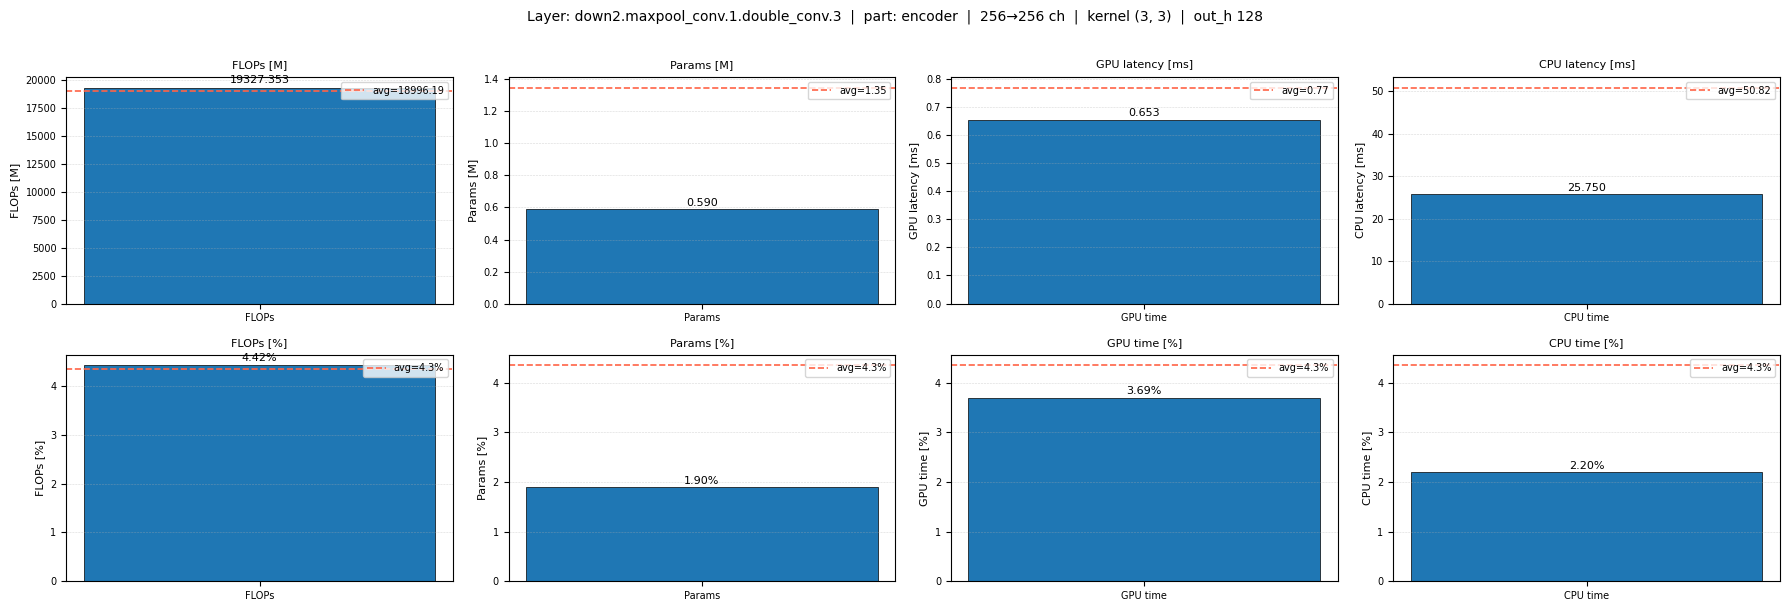

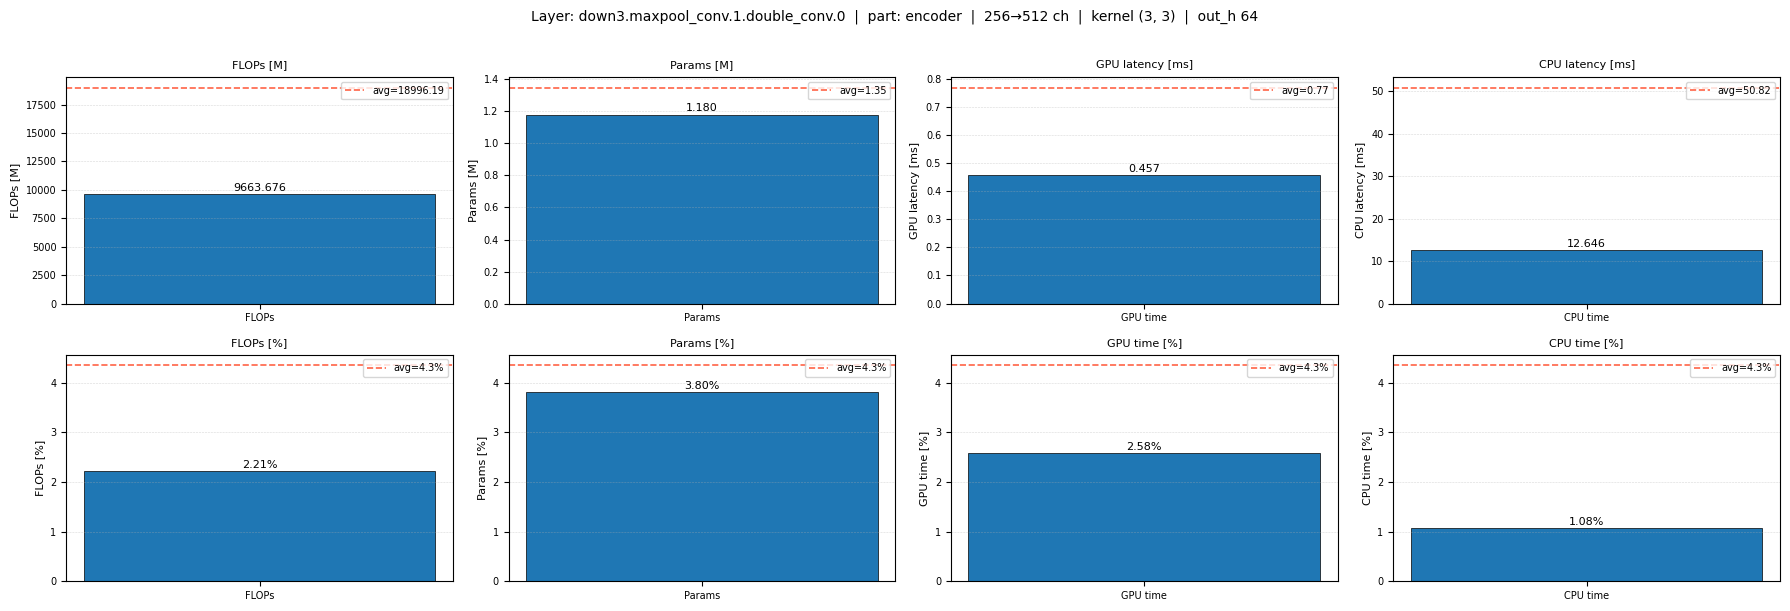

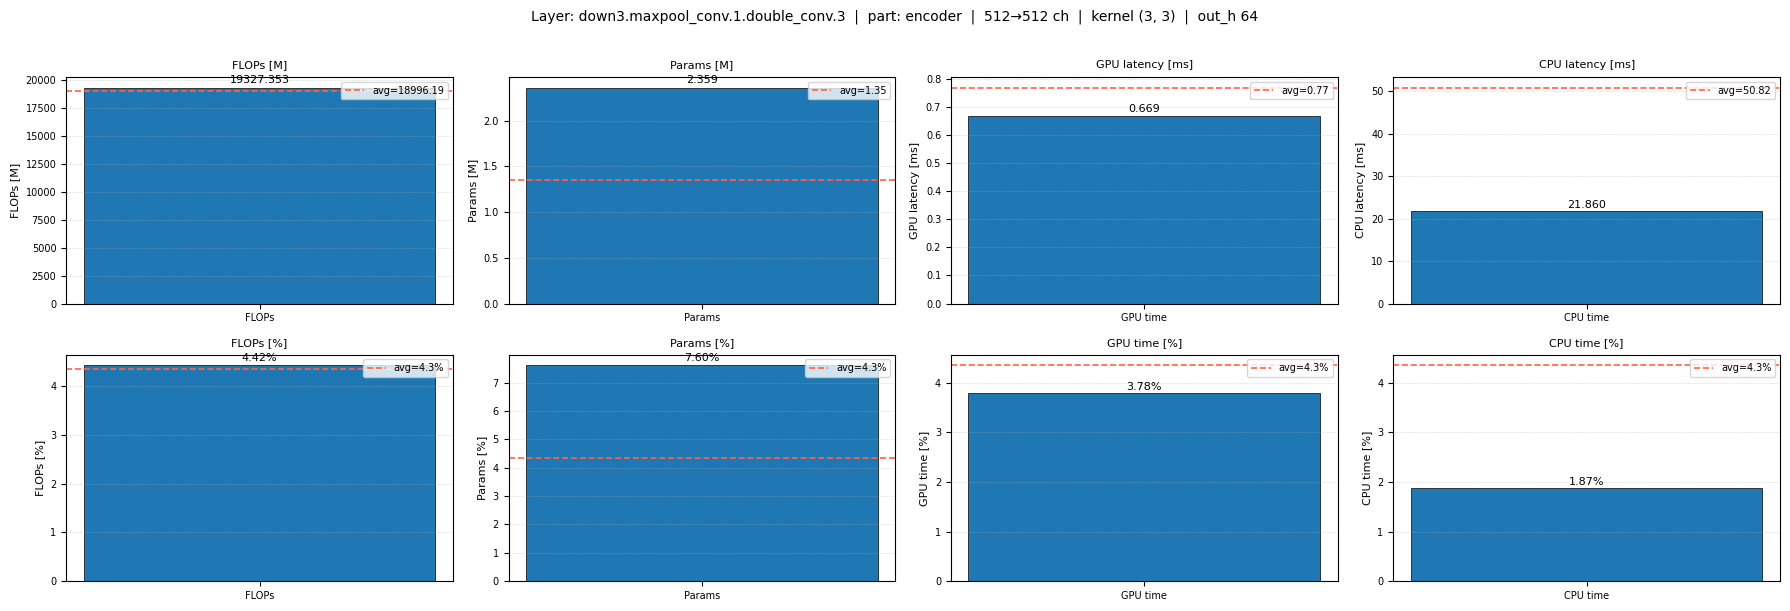

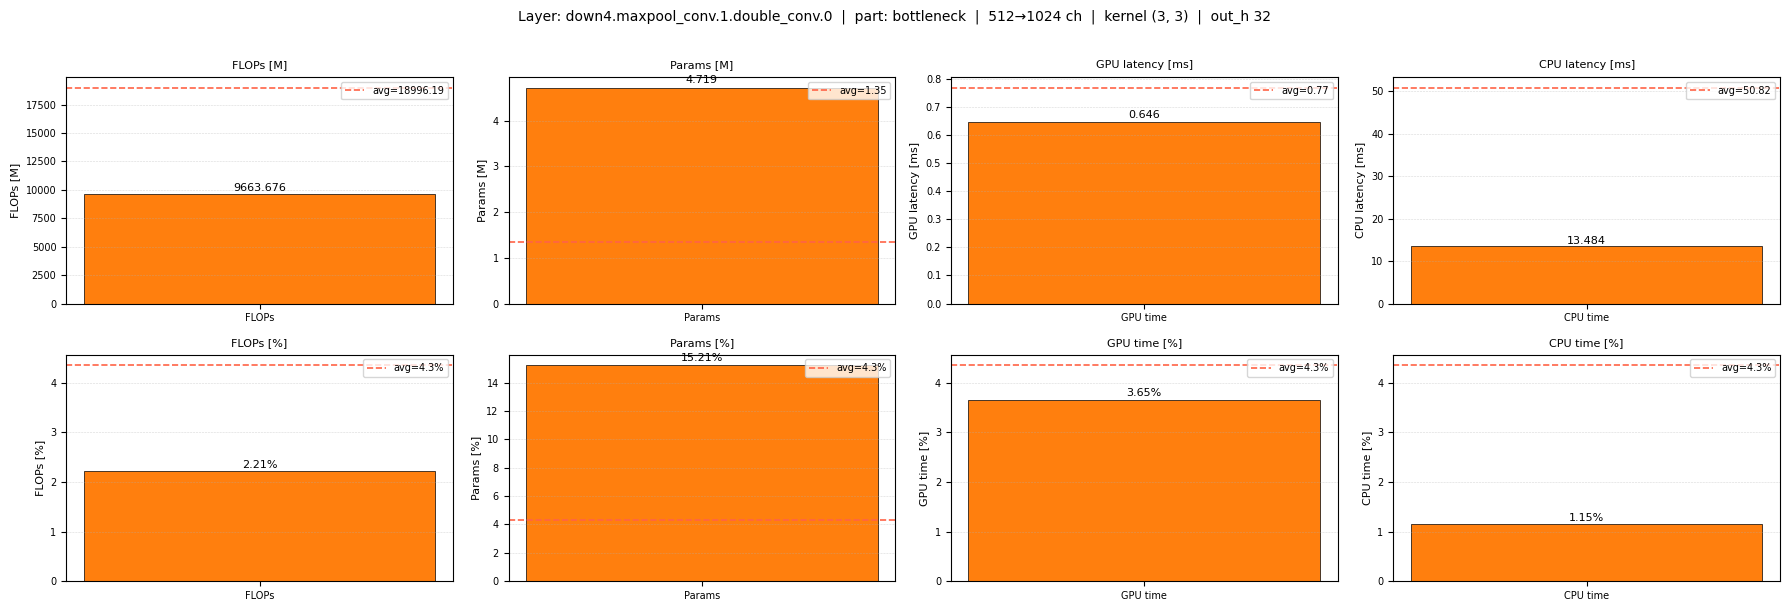

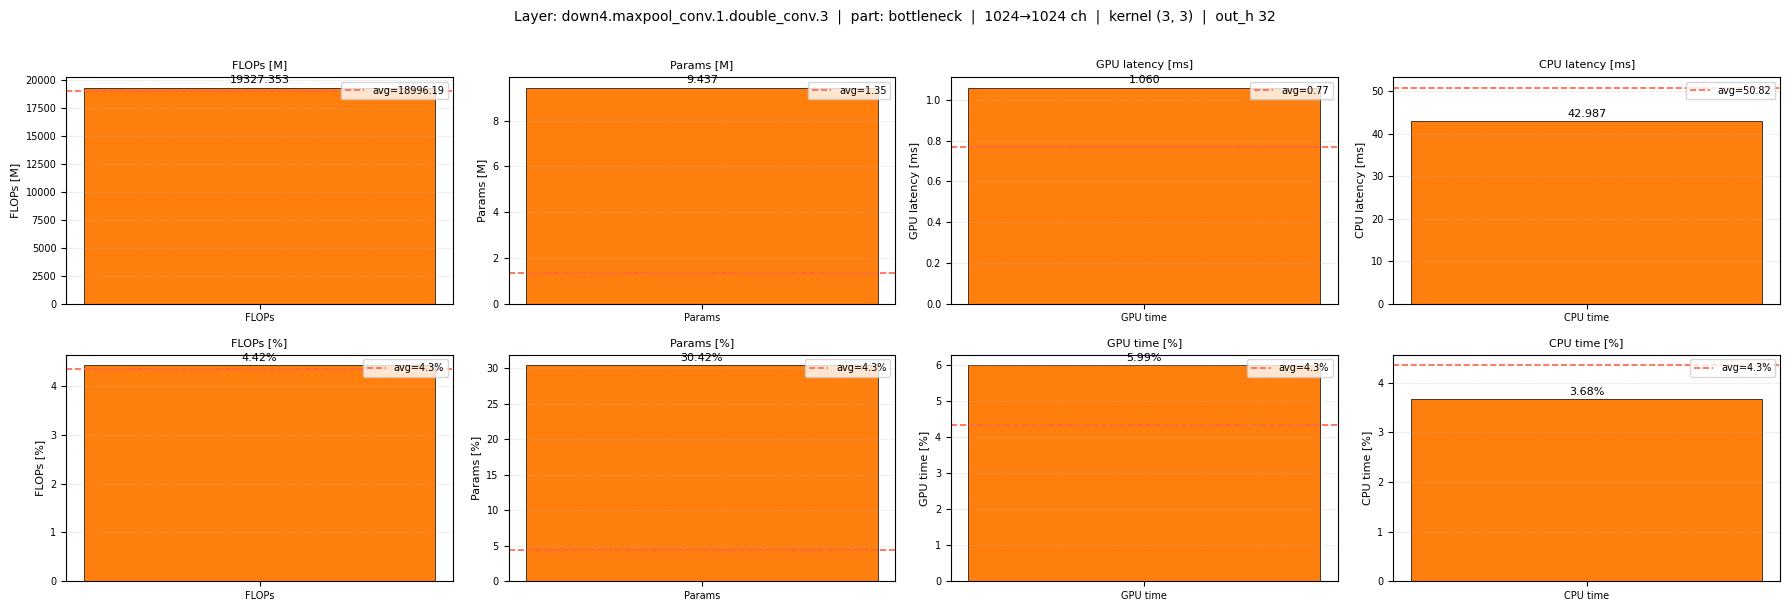

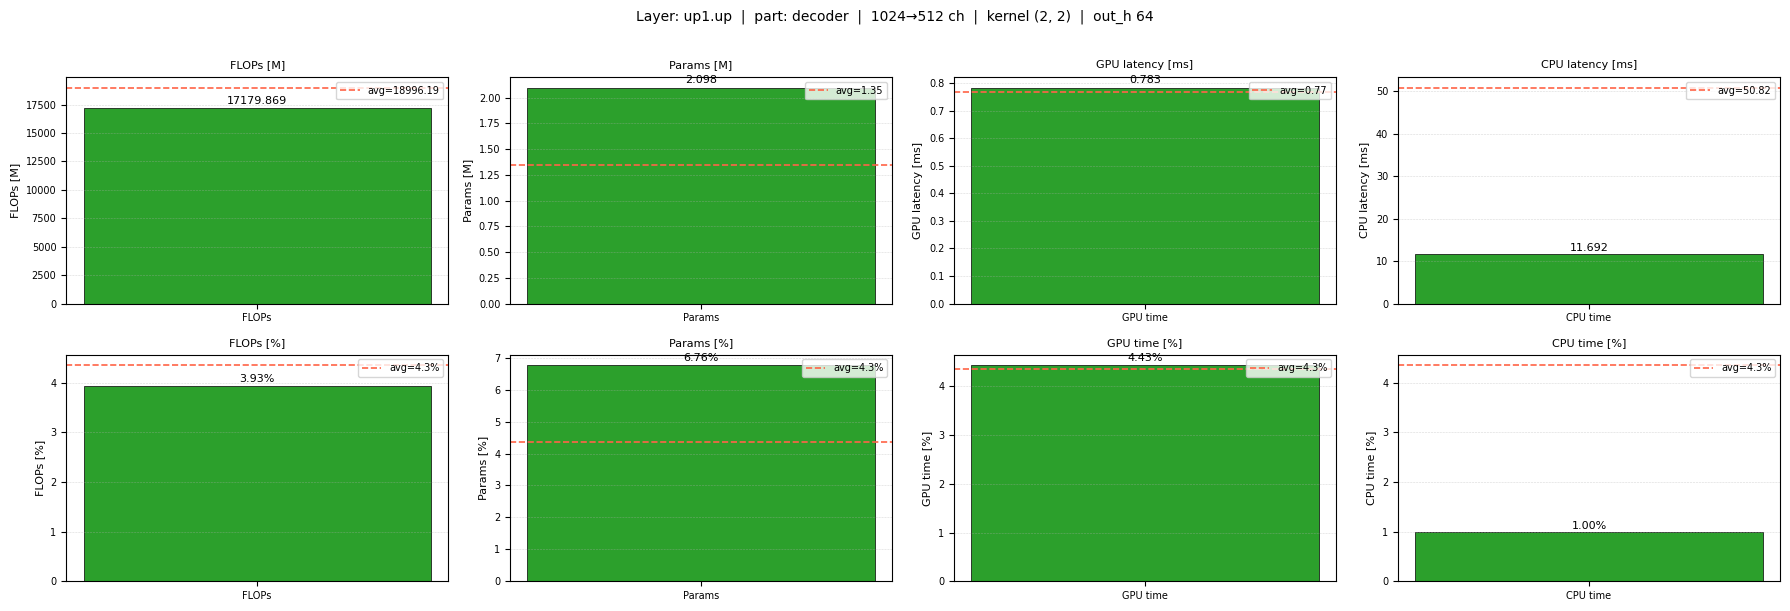

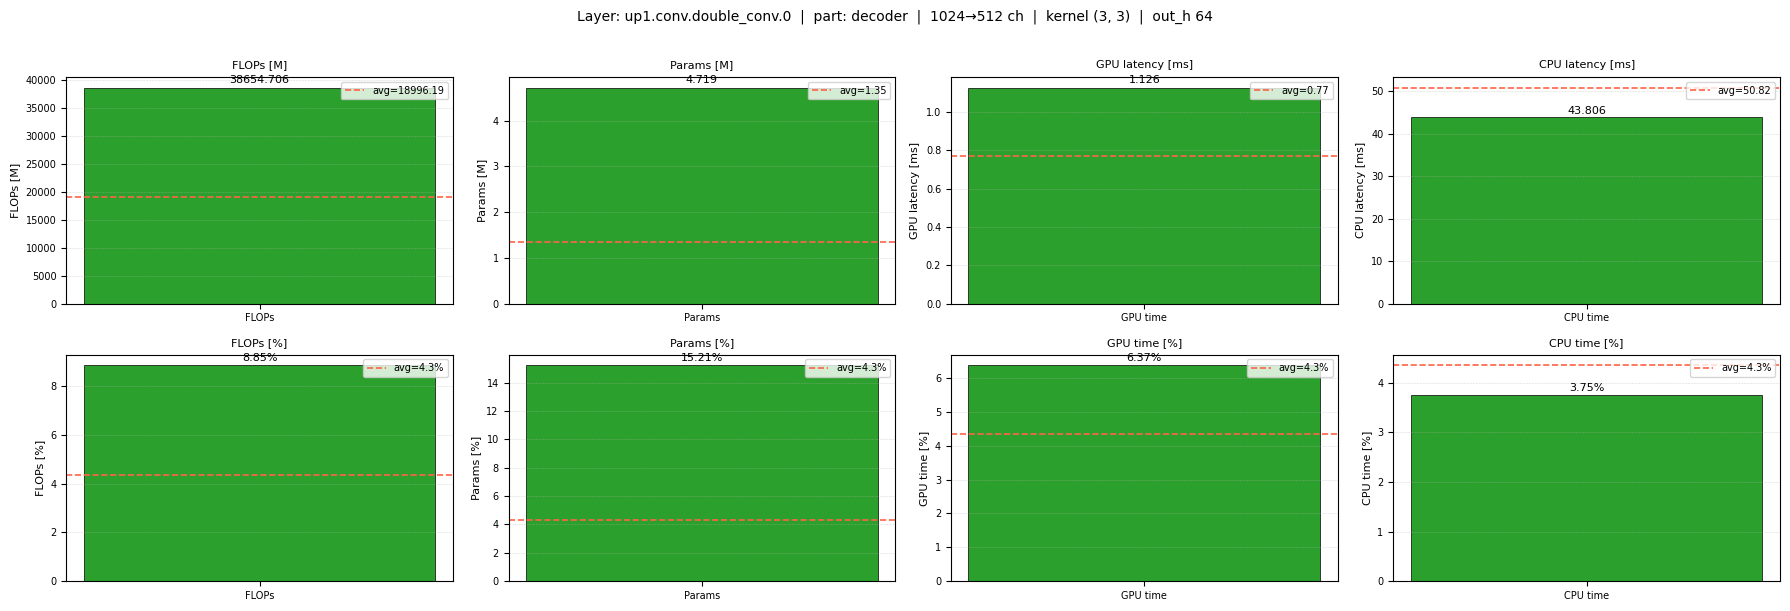

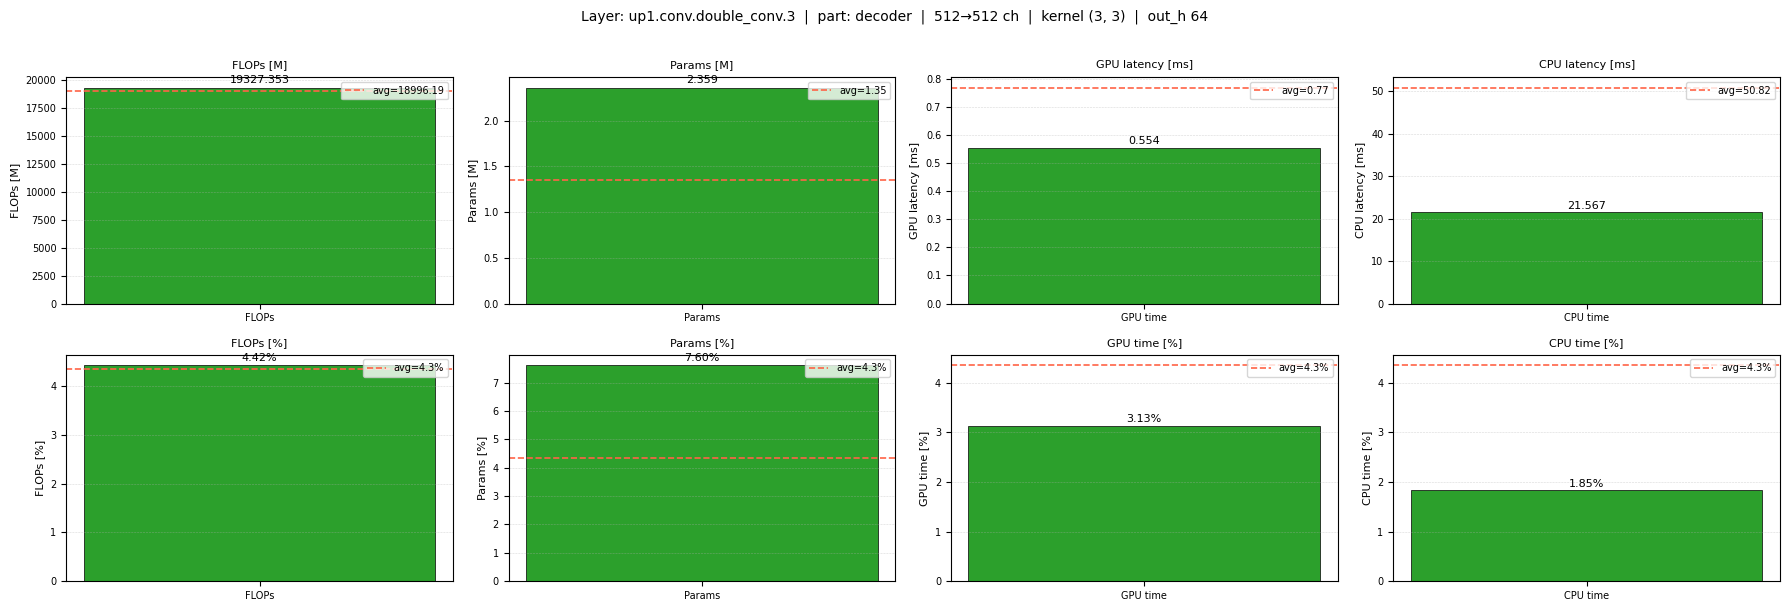

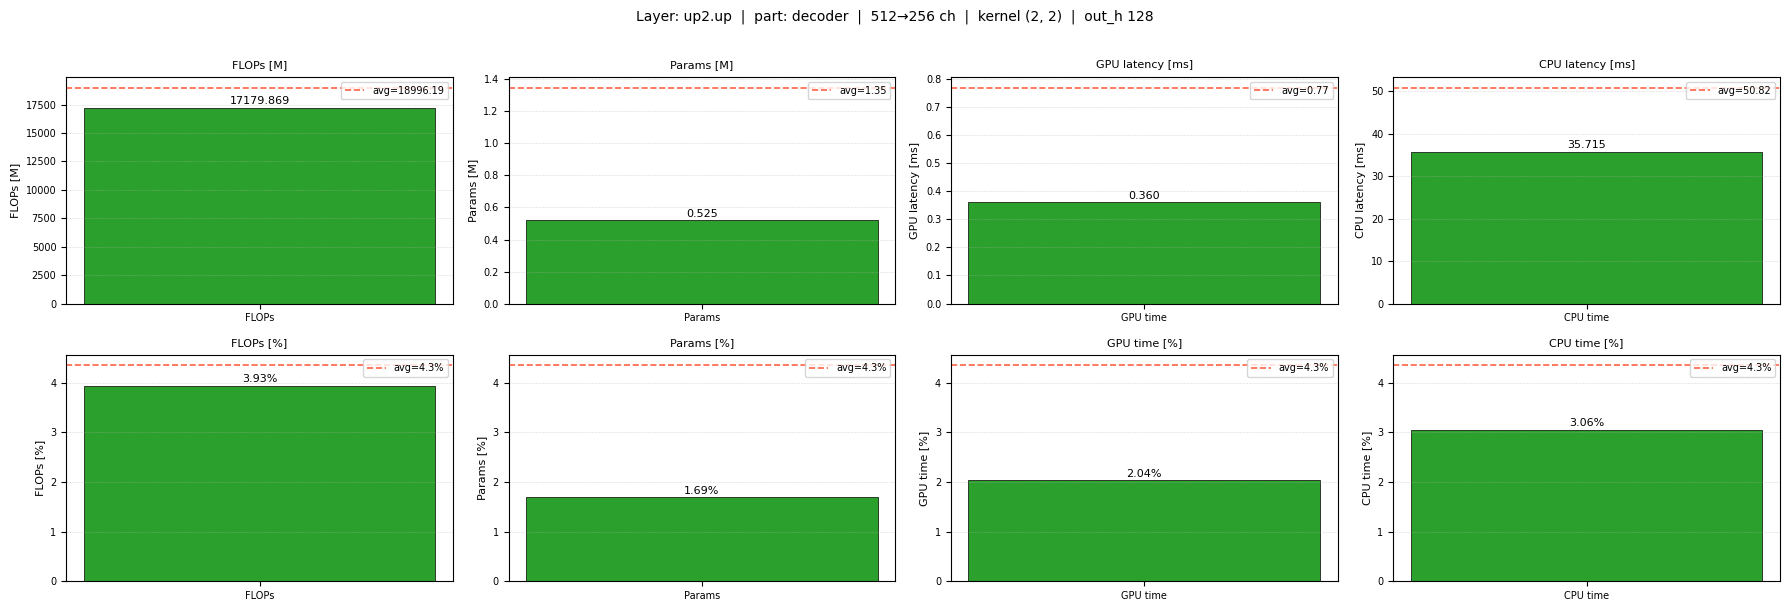

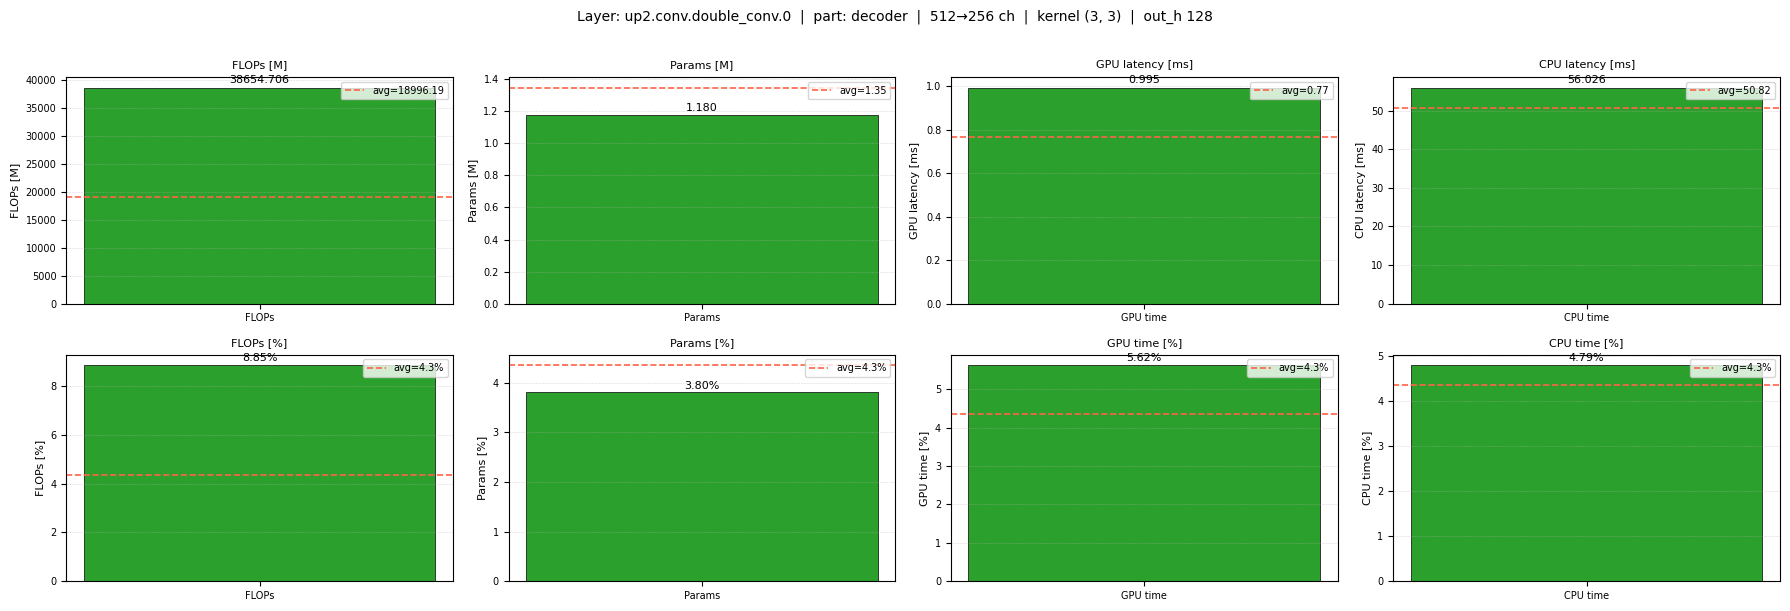

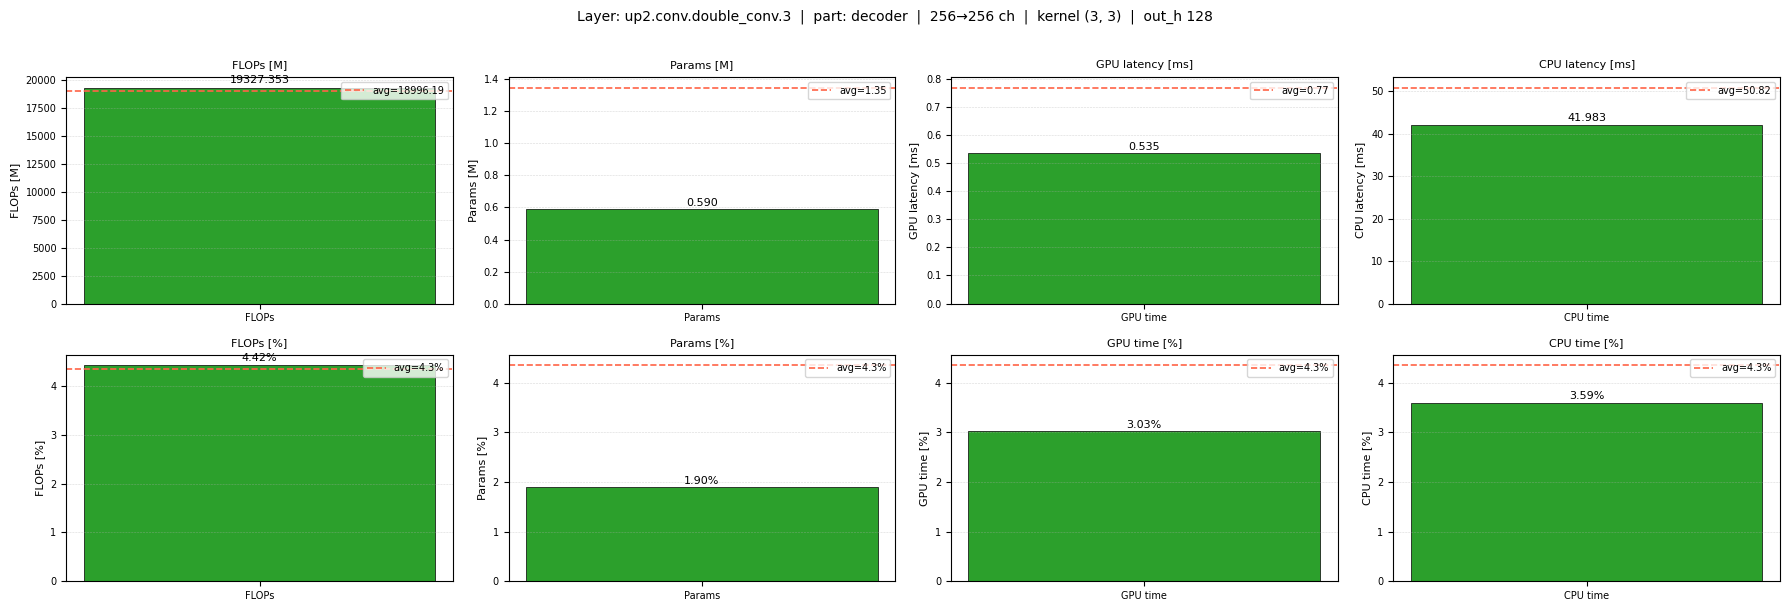

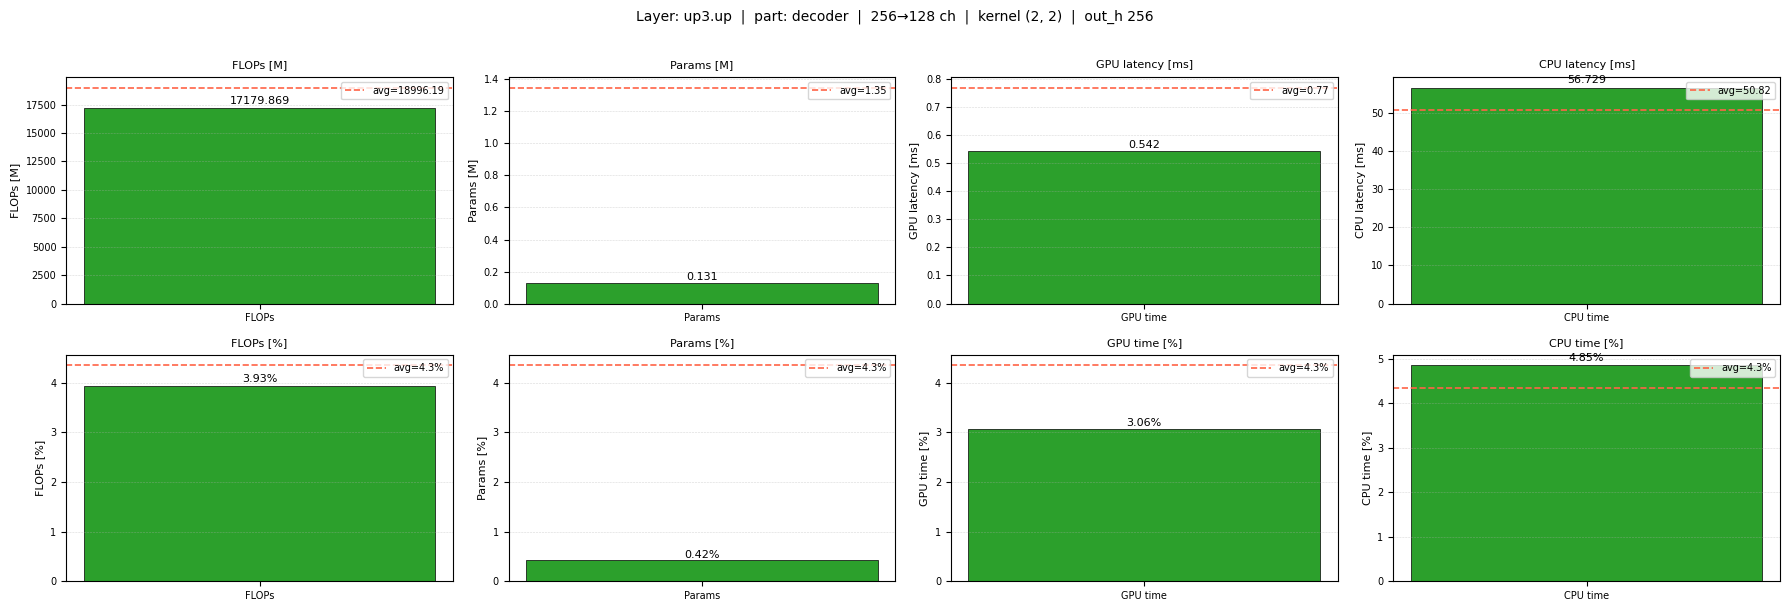

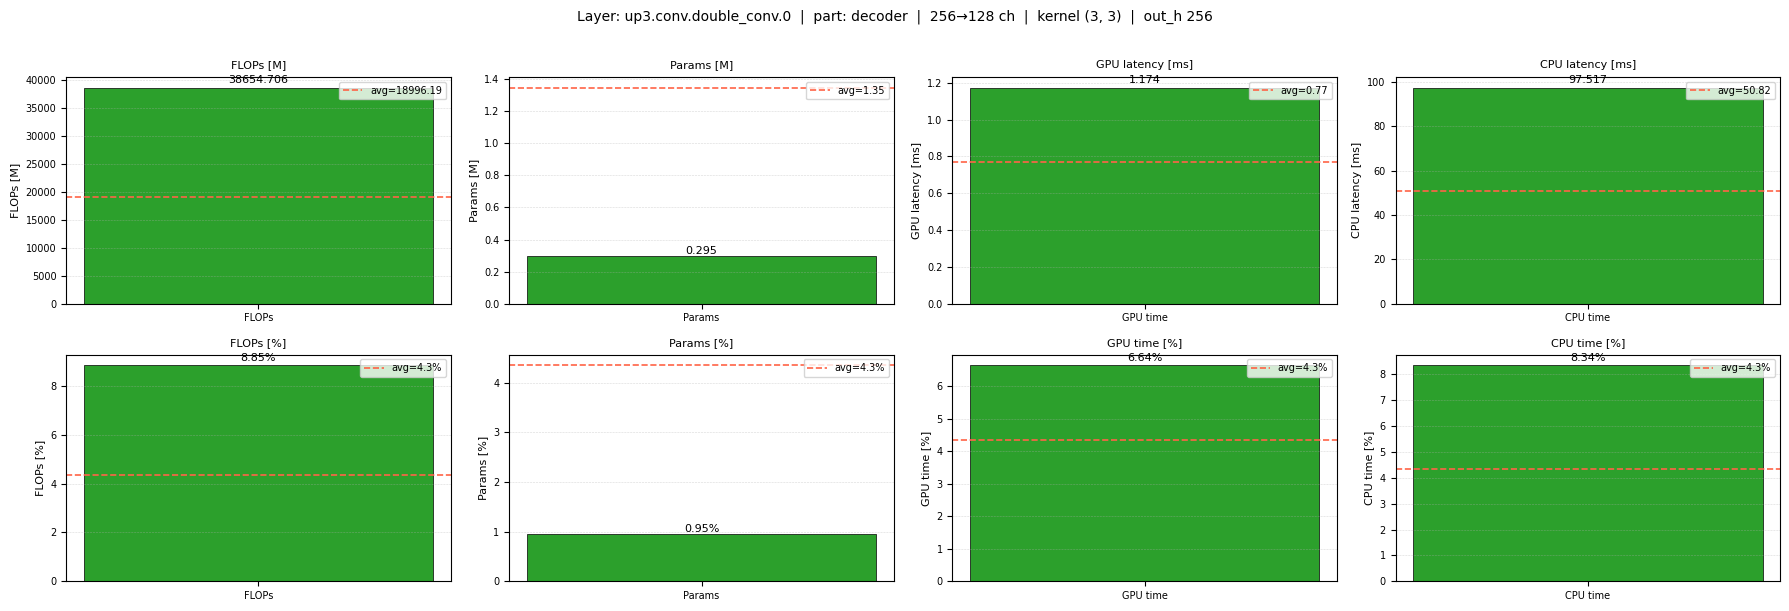

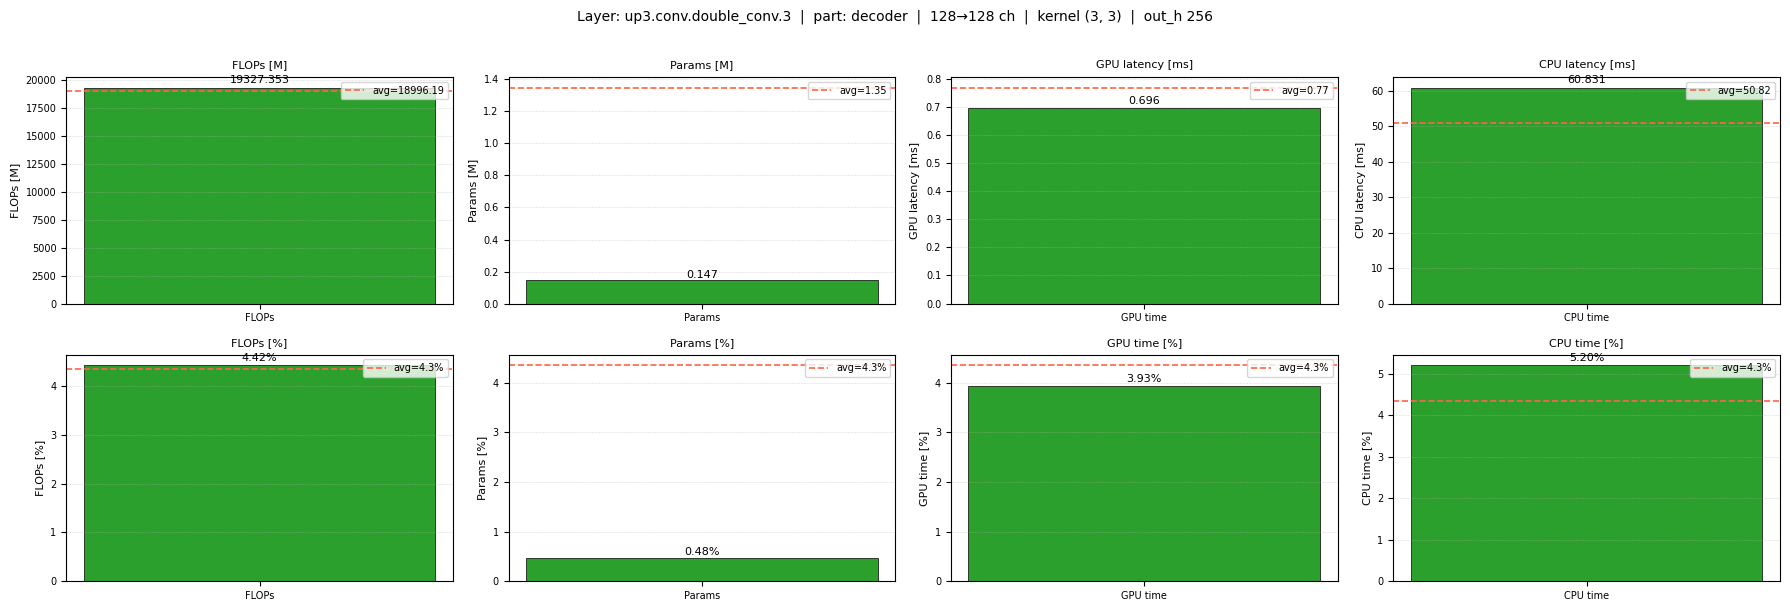

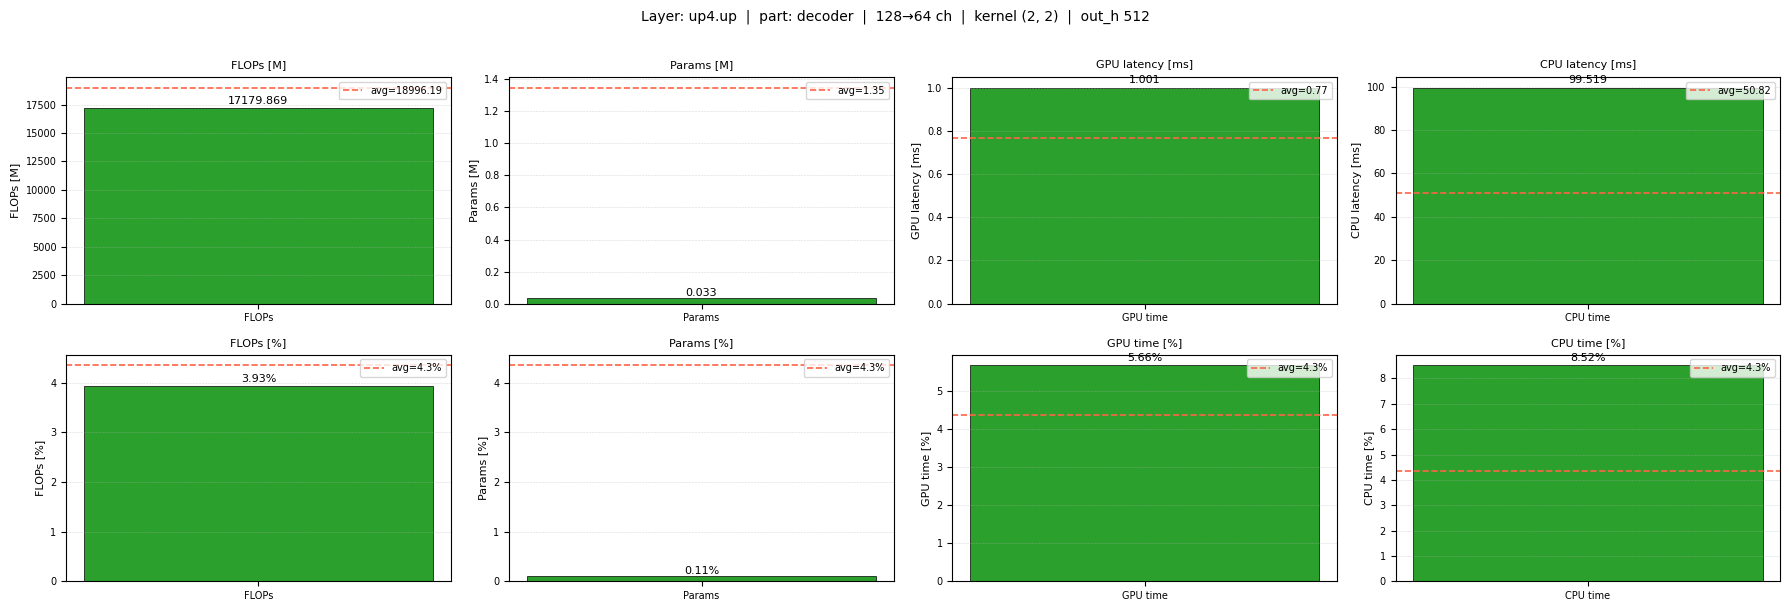

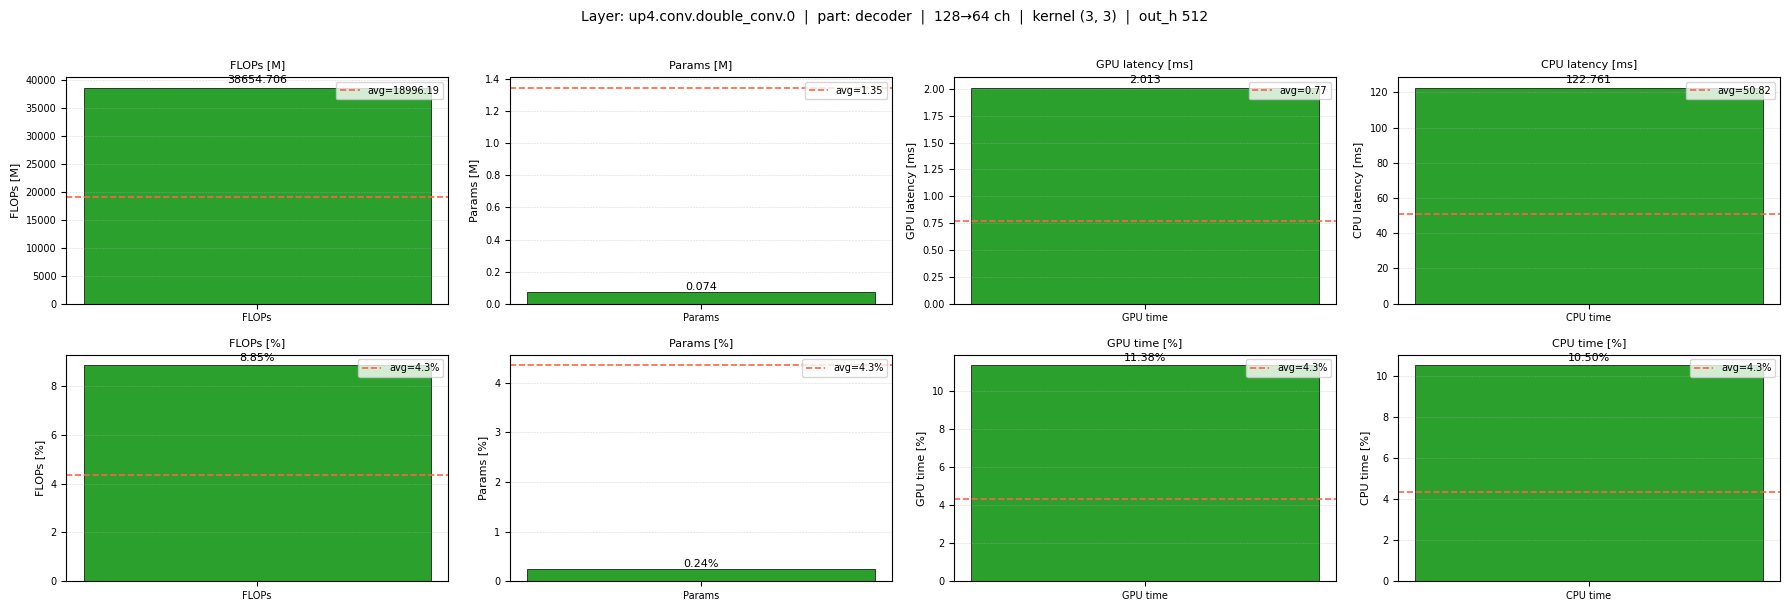

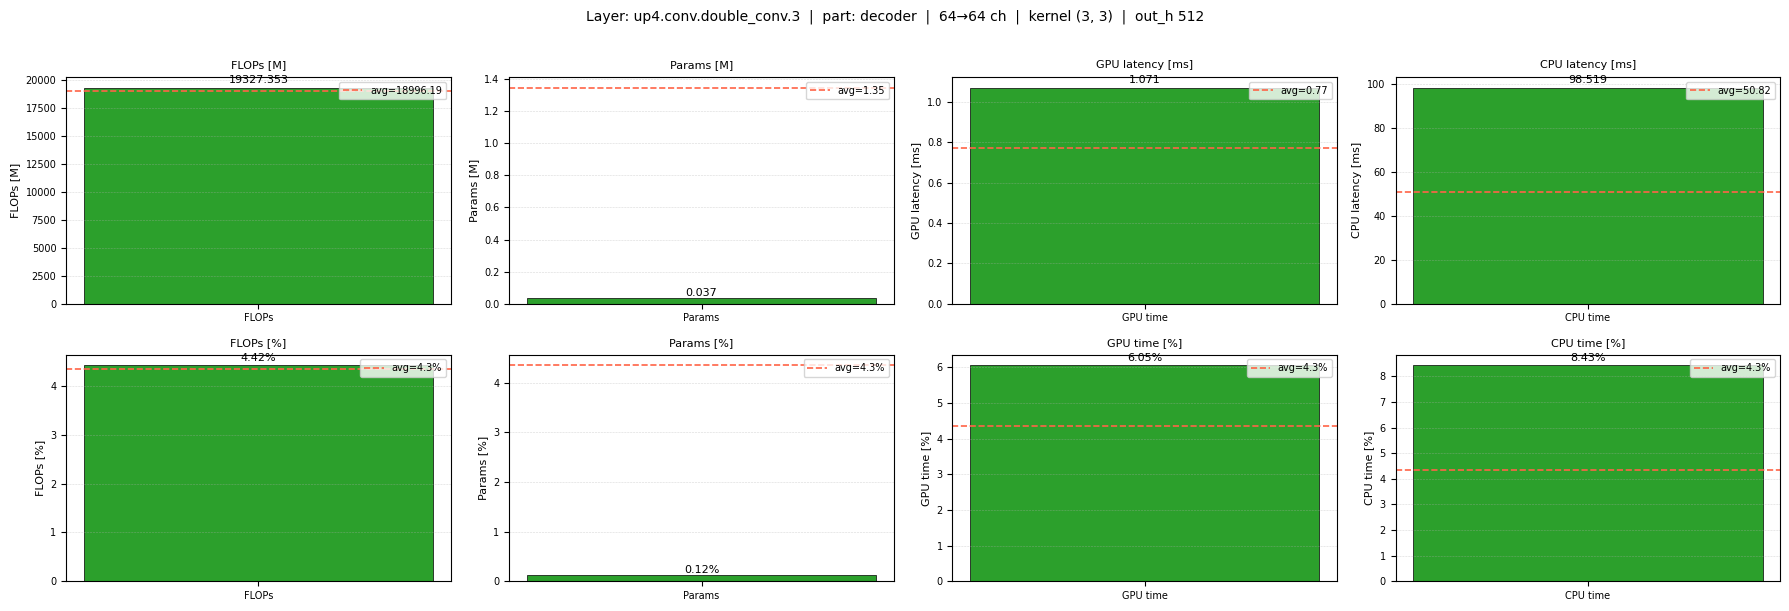

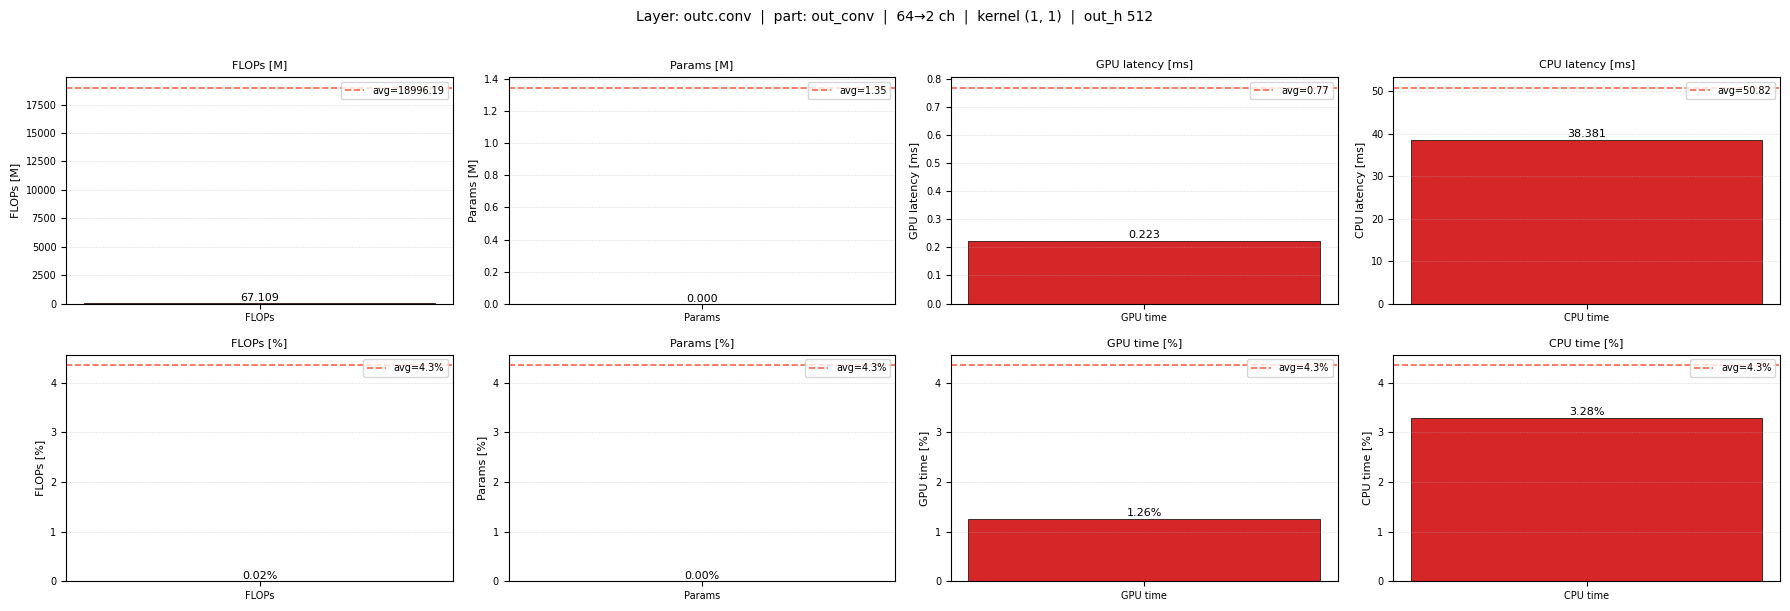

In [23]:
# ── 2.13  Combined 4-metric per-layer grid (absolute + percentage) ────────────
#
# Layout: one figure per layer, 2 rows × 4 cols
#   Row 0: absolute values  (FLOPs M | params M | GPU ms | CPU ms)
#   Row 1: % of model total (FLOPs % | params % | GPU %  | CPU %)
#
# Each bar is the layer's value; a dashed red line shows the average across layers.
# Bars are colored by U-Net part.

METRICS_ABS = [
    ("flops_M",      "FLOPs [M]",       "FLOPs"),
    ("params_M",     "Params [M]",      "Params"),
    ("time_gpu_ms",  "GPU latency [ms]","GPU time"),
    ("time_cpu_ms",  "CPU latency [ms]","CPU time"),
]
METRICS_PCT = [
    ("flops_pct",    "FLOPs [%]",       "FLOPs"),
    ("params_pct",   "Params [%]",      "Params"),
    ("gpu_pct",      "GPU time [%]",    "GPU time"),
    ("cpu_pct",      "CPU time [%]",    "CPU time"),
]

# Compute percentage columns once
_df = df_layers.copy()
for abs_col, pct_col in [
    ("flops_M",     "flops_pct"),
    ("params_M",    "params_pct"),
    ("time_gpu_ms", "gpu_pct"),
    ("time_cpu_ms", "cpu_pct"),
]:
    total = _df[abs_col].sum()
    _df[pct_col] = 100.0 * _df[abs_col] / (total + 1e-12)

df_layers_pct = _df   # keep enriched copy for use below


def plot_layer_4metric_grid(df: pd.DataFrame,
                            layer_name: str,
                            part_colors: dict,
                            figsize=(18, 6)):
    """
    For a single layer: 2-row × 4-col grid.
    Row 0 = absolute metrics, Row 1 = % of model total.
    A dashed red line marks the cross-layer average for context.
    """
    row = df[df["layer_name"] == layer_name]
    if row.empty:
        print(f"Layer '{layer_name}' not found.")
        return
    row = row.iloc[0]
    color = part_colors.get(str(row.get("part", "")), "gray")

    fig, axes = plt.subplots(2, 4, figsize=figsize)
    fig.suptitle(
        f"Layer: {layer_name}  |  part: {row.get('part','?')}  "
        f"|  {int(row.get('in_ch',0))}→{int(row.get('out_ch',0))} ch  "
        f"|  kernel {row.get('kernel','?')}  |  out_h {int(row.get('out_h',0))}",
        fontsize=10, y=1.01
    )

    for col_idx, ((abs_col, abs_label, short), (pct_col, pct_label, _)) in enumerate(
            zip(METRICS_ABS, METRICS_PCT)):

        # ── Row 0: absolute ──────────────────────────────────────────────
        ax_abs = axes[0, col_idx]
        val    = float(row[abs_col])
        avg    = float(df[abs_col].mean())
        ax_abs.bar([short], [val], color=color, edgecolor="black", linewidth=0.5, width=0.5)
        ax_abs.axhline(avg, color="tomato", ls="--", lw=1.2, label=f"avg={avg:.2f}")
        ax_abs.set_ylabel(abs_label, fontsize=8)
        ax_abs.set_title(abs_label, fontsize=8)
        ax_abs.legend(fontsize=7, loc="upper right")
        ax_abs.tick_params(labelsize=7)
        ax_abs.grid(axis="y", ls="--", lw=0.4, alpha=0.5)
        # annotate bar
        ax_abs.text(0, val * 1.01, f"{val:.3f}", ha="center", va="bottom", fontsize=8)

        # ── Row 1: percentage ────────────────────────────────────────────
        ax_pct = axes[1, col_idx]
        pval   = float(row[pct_col])
        pavg   = float(df[pct_col].mean())
        ax_pct.bar([short], [pval], color=color, edgecolor="black", linewidth=0.5, width=0.5)
        ax_pct.axhline(pavg, color="tomato", ls="--", lw=1.2, label=f"avg={pavg:.1f}%")
        ax_pct.set_ylabel(pct_label, fontsize=8)
        ax_pct.set_title(pct_label, fontsize=8)
        ax_pct.legend(fontsize=7, loc="upper right")
        ax_pct.tick_params(labelsize=7)
        ax_pct.grid(axis="y", ls="--", lw=0.4, alpha=0.5)
        ax_pct.text(0, pval * 1.01, f"{pval:.2f}%", ha="center", va="bottom", fontsize=8)

    plt.tight_layout()
    plt.show()


# ── All-layers summary grid: all layers side by side ─────────────────────────
def plot_all_layers_4metric(df: pd.DataFrame,
                            part_colors: dict,
                            figsize=(22, 10)):
    """
    2-row × 4-col grid.  Within each panel all layers are shown as a bar chart,
    colored by part.  Row 0 = absolute, Row 1 = percentage.
    This is the "overview" version complementary to the per-layer detail above.
    """
    # order layers network-forward
    order = [
        "inc.double_conv.0", "inc.double_conv.3",
        "down1.maxpool_conv.1.double_conv.0", "down1.maxpool_conv.1.double_conv.3",
        "down2.maxpool_conv.1.double_conv.0", "down2.maxpool_conv.1.double_conv.3",
        "down3.maxpool_conv.1.double_conv.0", "down3.maxpool_conv.1.double_conv.3",
        "down4.maxpool_conv.1.double_conv.0", "down4.maxpool_conv.1.double_conv.3",
        "up1.up", "up1.conv.double_conv.0", "up1.conv.double_conv.3",
        "up2.up", "up2.conv.double_conv.0", "up2.conv.double_conv.3",
        "up3.up", "up3.conv.double_conv.0", "up3.conv.double_conv.3",
        "up4.up", "up4.conv.double_conv.0", "up4.conv.double_conv.3",
        "outc.conv",
    ]
    # keep only layers present in df, in forward order
    present = set(df["layer_name"].tolist())
    ordered = [l for l in order if l in present]
    # append any remaining not in our order list
    ordered += [l for l in df["layer_name"].tolist() if l not in ordered]
    df_ord = df.set_index("layer_name").reindex(ordered).dropna(how="all").reset_index()

    labels = [".".join(n.split(".")[-2:]) if "." in n else n
              for n in df_ord["layer_name"]]
    colors = [part_colors.get(str(p), "gray") for p in df_ord["part"]]
    x = np.arange(len(labels))

    fig, axes = plt.subplots(2, 4, figsize=figsize)
    fig.suptitle("All layers — 4-metric overview (absolute + % of total)",
                 fontsize=12, y=1.01)

    for col_idx, ((abs_col, abs_label, short), (pct_col, pct_label, _)) in enumerate(
            zip(METRICS_ABS, METRICS_PCT)):

        # Row 0: absolute
        ax = axes[0, col_idx]
        vals = df_ord[abs_col].fillna(0).values
        ax.bar(x, vals, color=colors, edgecolor="black", linewidth=0.3, width=0.7)
        ax.axhline(vals.mean(), color="tomato", ls="--", lw=1, label=f"mean={vals.mean():.2f}")
        ax.set_xticks(x); ax.set_xticklabels(labels, rotation=90, fontsize=6)
        ax.set_ylabel(abs_label, fontsize=8); ax.set_title(abs_label, fontsize=9)
        ax.legend(fontsize=7); ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)

        # Row 1: percentage
        ax = axes[1, col_idx]
        pvals = df_ord[pct_col].fillna(0).values
        ax.bar(x, pvals, color=colors, edgecolor="black", linewidth=0.3, width=0.7)
        ax.axhline(pvals.mean(), color="tomato", ls="--", lw=1, label=f"mean={pvals.mean():.1f}%")
        ax.set_xticks(x); ax.set_xticklabels(labels, rotation=90, fontsize=6)
        ax.set_ylabel(pct_label, fontsize=8); ax.set_title(pct_label, fontsize=9)
        ax.legend(fontsize=7); ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)

    # Part legend
    from matplotlib.patches import Patch
    handles = [Patch(facecolor=c, edgecolor="black", label=p)
               for p, c in part_colors.items()
               if p in df["part"].values]
    fig.legend(handles=handles, loc="lower center", ncol=len(handles),
               fontsize=8, title="U-Net part", bbox_to_anchor=(0.5, -0.02))
    plt.tight_layout()
    plt.show()


# ── Run ───────────────────────────────────────────────────────────────────────
# Overview: all layers in one figure
plot_all_layers_4metric(df_layers_pct, PART_COLORS)

# Per-layer detail: one figure per conv layer
for lname in df_layers_pct["layer_name"].tolist():
    plot_layer_4metric_grid(df_layers_pct, lname, PART_COLORS)


In [24]:
out_path = Path('unet_layer_profiling_results.csv')
df_layers.to_csv(out_path, index=False)
print(f'Saved to {out_path.resolve()}')

budget_path = Path('unet_pruning_budget.csv')
df_budget.to_csv(budget_path, index=False)
print(f'Saved to {budget_path.resolve()}')

Saved to /home/jovyan/cost-based-pruning-layer-by-layer/unet_layer_profiling_results.csv
Saved to /home/jovyan/cost-based-pruning-layer-by-layer/unet_pruning_budget.csv
